# GreenSite AI — Part 2: the website (Step 11)

This notebook builds the GreenSite website from the model results and runs it.

* **Part 1** (`GreenSite_1_Model_and_Map.ipynb`): data cleaning, K-Means, screening rules, ranking, the Top-20 shortlist and the Bokeh map (Steps 1 to 10B).
* **Part 2** (this notebook): loads Part 1, turns its results into a website, and starts the website with a link you can open.

| Step | What it does | Result |
|---|---|---|
| 11.0 | Run Part 1 (the model) | `map_df`, `shortlists_by_min_distance` |
| 11.1 | Settings, folders and download helpers | empty `greensite/` folder |
| 11.2 | Export the model results for the website, check the Top-20 | `data/cells.json` |
| 11.3 | Governorate borders (Natural Earth) | `data/iraq.geojson`, `data/iraq-outline.geojson` |
| 11.4 | Libraries: MapLibre, Three.js, fonts (npm, md5-checked) | `assets/vendor/` |
| 11.5 | Earth textures (NASA Blue Marble / Black Marble) | `assets/earth/` |
| 11.6 | Cube images (the team's render, stored in this notebook) | `assets/cube/`, `assets/cube.webp` |
| 11.7 | Website source code: HTML, CSS, JavaScript | `index.html`, `assets/*.css`, `assets/*.js` |
| 11.8 | Check the site and start it | a link to the running website |
| 11.9 | Optional: download the site folder | `greensite-site.zip` |

**The website has no back-end.** It is a folder of static files (HTML, CSS, JavaScript, images and JSON data) that the browser reads directly. All heavy work (cleaning, K-Means, rules, ranking) happens once in Part 1; the website only shows the results and filters them.

**How to run:** put both notebooks in the same folder (in Colab: upload `GreenSite_1_Model_and_Map.ipynb` to the *Files* panel, or keep both in the same Google Drive folder), then `Runtime → Run all`. Part 1 asks for the raw CSV as usual. This notebook needs internet for the libraries, the borders and the Earth images.

Saving greensite_baghdad_raw.csv to greensite_baghdad_raw.csv
Loaded file: greensite_baghdad_raw.csv
Missing required columns: none
Shape (rows, columns): (246451, 20)
Date range: 2023-01-01 to 2026-05-01
Unique cells: 6011
Duplicate (cell_id, date) rows: 0
Observations per cell (count: number of cells): {41: 6011}


,missing,percent
ndvi_raw,0,0.000
ndvi_summary_qa,0,0.000
temperature_2m_K,0,0.000
total_precipitation_m,0,0.000
soil_moisture_vwc_layer1,0,0.000
soil_ph_x10,29725,12.061
soil_organic_carbon_dg_kg,29602,12.011
sand_g_kg,29725,12.061
clay_g_kg,29725,12.061
land_cover_code,0,0.000


Month gaps that are not exactly 1: 0
Months in file: 41 | cells with a different number of months: 0
Dates that are not the 1st of a month: 0


,ndvi,temperature_c,precipitation_mm
count,246451.000,246451.000,246451.000
mean,0.257,25.155,17.820
std,0.128,9.738,26.136
min,-0.059,9.704,0.016
25%,0.146,16.111,0.030
50%,0.239,26.187,4.810
75%,0.350,34.596,27.817
max,0.754,40.420,170.229


NDVI outside -1..1: 0
ndvi_raw equal to the MODIS fill value -3000: 0
Share of negative total_evaporation_m rows: 1.0
(Negative evaporation is normal for ERA5: it is a sign convention, not an error. We do not use evaporation here.)
Quality flag counts:
ndvi_summary_qa
0    225991
1     19222
3      1238
Name: count, dtype: int64

Share of reliable observations: 0.995
Cells with at least one unreliable month: 690
Recent window: 2025-06-01 to 2026-05-01
Previous window: 2024-06-01 to 2025-05-01
Cells with too few reliable months (recent / previous): 0 / 0
Mean 12-month precipitation (mm), recent vs previous: 257 vs 120
Weather differs between years, so an NDVI change is not automatically land degradation.
Cells with a seasonal anomaly: 6008
Average number of earlier observations behind each monthly baseline: 2.41
Cells: 6011 | cells with missing soil data (kept): 756
Distinct climate values (coarse climate pixels): 74
One land-cover code per cell: True
Codes not in the WorldCover list: n

,cells,mean_recent_ndvi
land_cover_name,,
Bare / sparse vegetation,1547,0.176
Built-up,791,0.154
Cropland,2296,0.300
Grassland,88,0.130
Permanent water,218,0.265
Shrubland,262,0.236
Tree cover,809,0.337


Cells clustered: 6008 | not clustered (missing evidence): 3
Silhouette score (sample of 3000 cells): 0.411
Reading: weak to moderate structure: the clusters are partly separated but overlap
Remember: this measures separation between groups only. It says nothing about degradation or planting success.


,recent_mean_ndvi_mean,recent_mean_ndvi_median,recent_ndvi_change_mean,recent_ndvi_change_median,seasonal_anomaly_mean,seasonal_anomaly_median,cells,share_built_up
cluster_id,,,,,,,,
0,0.152,0.138,-0.000,0.001,-0.006,-0.005,2559,0.265
1,0.219,0.216,-0.056,-0.045,-0.052,-0.046,685,0.007
2,0.343,0.343,0.016,0.016,0.005,0.004,2764,0.038


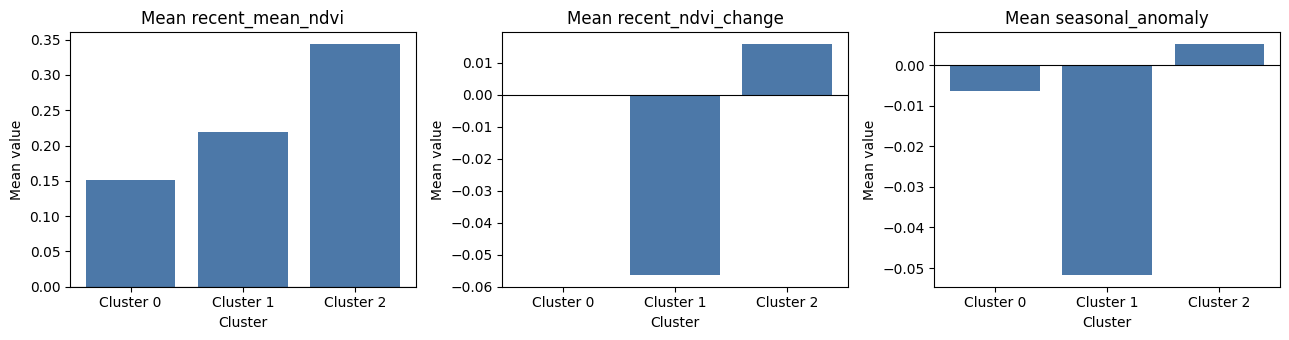

Std of recent_ndvi_change: 0.029 | std of seasonal_anomaly: 0.024
Low-NDVI cutoff (recent 12-month mean NDVI, 25th percentile): 0.146
Flagged cells -> low NDVI: 1503 | declining: 559 | below seasonal: 696
{'Stable': 4928, 'Declining': 559, 'Increasing': 524}
intervention_category
Lower screening priority       3849
Moderate screening priority    1648
Higher screening priority       514
Name: count, dtype: int64
Organic carbon median: 8.5 g/kg | sand upper limit: 166 g/kg
greening_potential_category
Mixed                       3327
More promising              1553
Needs further assessment     926
Less promising               205
Name: count, dtype: int64
Soil pH range across cells: 7.7 to 8.0 (too narrow to separate cells, so not used)


final_priority,High,Low,Medium
candidate_group,,,
Built-up cell (land use must be inspected),0,288,503
Low-vegetation open area,130,0,861
No clear signal,0,3373,0
Vegetated area with decline,374,0,264
Water / mixed cell (inspect),0,188,30


                                                                                                                                                                             short_reason                                                                                              data_uncertainty
cell_id                                                                                                                                                                                                                                                                                                
0        Recent NDVI 0.42; change vs previous 12 months +0.00; vs usual same-month level -0.00. Signals: no signal. Soil: organic carbon 8.8 g/kg, sand 222 g/kg. Group: No clear signal.  already tree cover (care may matter more than new planting); land cover is a single value at the cell centre
1        Recent NDVI 0.41; change vs previous 12 months +0.04; vs usual same-month level +0.01. Signals: no sign

,rank,cell_id,latitude,longitude,recent_mean_ndvi,recent_ndvi_change,intervention_category,greening_potential_category,final_priority,candidate_group,land_cover_name
0,1,3943,33.196,44.888,0.144,-0.146,Higher screening priority,More promising,High,Low-vegetation open area,Cropland
1,2,4041,33.187,44.854,0.136,-0.188,Higher screening priority,Mixed,High,Low-vegetation open area,Cropland
2,3,4322,33.162,44.841,0.143,-0.164,Higher screening priority,Mixed,High,Low-vegetation open area,Cropland
3,4,4040,33.187,44.844,0.137,-0.162,Higher screening priority,Mixed,High,Low-vegetation open area,Cropland
4,5,3940,33.196,44.858,0.141,-0.157,Higher screening priority,Mixed,High,Low-vegetation open area,Cropland
5,6,4233,33.171,44.845,0.143,-0.147,Higher screening priority,Mixed,High,Low-vegetation open area,Cropland
6,7,4411,33.154,44.847,0.130,-0.143,Higher screening priority,Mixed,High,Low-vegetation open area,Cropland
7,8,3831,33.204,44.773,0.138,-0.126,Higher screening priority,Mixed,High,Low-vegetation open area,Bare / sparse vegetation
8,9,3731,33.212,44.767,0.117,-0.113,Higher screening priority,Mixed,High,Low-vegetation open area,Bare / sparse vegetation
9,10,3634,33.221,44.851,0.142,-0.113,Higher screening priority,Mixed,High,Low-vegetation open area,Cropland


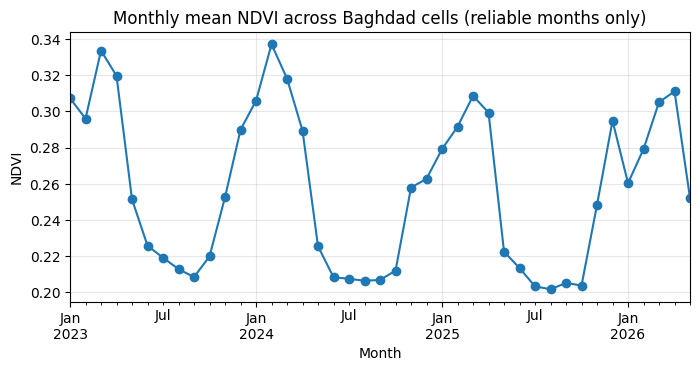

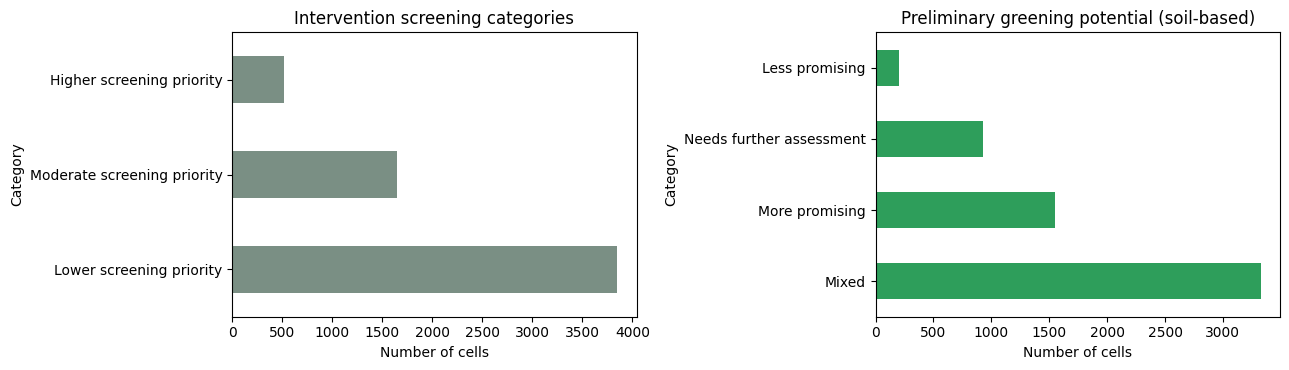

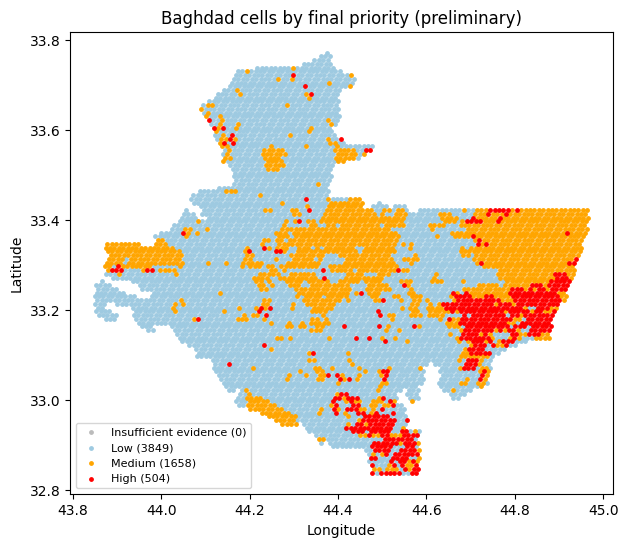

Saved 4 files. Rows: 6011 (all cells) / 100 (top candidates)


,passed
Raw data unchanged,True
ndvi_raw values unchanged in the working copy,True
NDVI scaled once (inside -1..1 and equal to ndvi_raw x 0.0001),True
Histories stay inside each cell (no month gaps),True
Unreliable NDVI never used (ndvi_valid empty where flag is not 0/1),True
K-Means inputs exclude coordinates,True
No planting-success column created,True
"Every cell is in the final table (none dropped, even with missing soil)",True
Coordinates valid in exported file,True


All checks passed: True
Cells with missing soil kept: 756 of 6011 cells
baghdad_cell_screening.csv            3451.5 KB
baghdad_top_candidates.csv              65.3 KB
baghdad_screening_summary.csv            0.9 KB
baghdad_scoring_metadata.json            3.1 KB


,flag_low_ndvi,flag_declining,flag_below_seasonal
cluster_label,,,
"Cluster 0: lowest recent NDVI, mean change -0.00",0.547,0.013,0.030
"Cluster 1: middle recent NDVI, mean change -0.06",0.149,0.758,0.888
"Cluster 2: highest recent NDVI, mean change +0.02",0.000,0.002,0.004
Not clustered (insufficient evidence),0.667,0.000,0.000


Climate pixels with the most top-100 candidates (compared with their share of all cells):


,share_of_top_100,share_of_all_cells
climate_group_id,,
53,0.340,0.020
49,0.160,0.010
26,0.130,0.018
55,0.100,0.020
69,0.060,0.019


Largest climate pixel holds 34% of the top 100 vs 2% of all cells (x16.8).
Interpretation: a regional pattern is likely (crop cycles, irrigation, land-use change). Verify these areas on satellite images before trusting them.
DATA-QUALITY VALIDATION
  Evidence: all promise checks passed: True; reliable NDVI share: 0.995
  Tells us: the pipeline kept the raw data intact, scaled NDVI once and never mixed cells
  Does NOT tell us: that the source data is correct or complete in the real world

K-MEANS CLUSTERING (SILHOUETTE)
  Evidence: silhouette = 0.411 -> weak to moderate structure: the clusters are partly separated but overlap
  Tells us: how well separated the groups are in the three NDVI indicators
  Does NOT tell us: whether k = 3 is best (not tuned), whether groups are degraded, or anything about planting success

RULE-BASED NEED SCREENING
  Evidence: category counts: {'Lower screening priority': 3849, 'Moderate screening priority': 1648, 'Higher screening priority': 514}
  Tells us

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Part 1 loaded: 6,011 cells


In [1]:
# ==============================================================================
# Step 11.0 — Run Part 1 (the model and the Bokeh map) inside this notebook
# `%run -i` executes every code cell of Part 1 here, so all its results (map_df,
# shortlists_by_min_distance, TOP_SITES_SPACING_KM, ...) become normal variables of this notebook.
# Part 1 asks you to upload the raw CSV, exactly as when you run it on its own.
# Expected result: Part 1's normal output, then "Part 1 loaded: 6,011 cells".
# ==============================================================================
from pathlib import Path

MODEL_NOTEBOOK = "GreenSite_1_Model_and_Map.ipynb"

# Look for Part 1 next to this notebook, then in Google Drive (if it is mounted).
search_places = [Path.cwd(), Path("/content"), Path("/content/drive/MyDrive")]
model_path = next((place / MODEL_NOTEBOOK for place in search_places if (place / MODEL_NOTEBOOK).is_file()), None)

if model_path is None:
    try:                                     # Colab: ask for the file instead of failing
        from google.colab import files
        print(f"{MODEL_NOTEBOOK} was not found. Please upload it:")
        uploaded_model = files.upload()
        model_path = Path(next(iter(uploaded_model)))
    except ImportError:
        raise FileNotFoundError(f"Put {MODEL_NOTEBOOK} in the same folder as this notebook.")

%run -i "{model_path}"

for needed in ["map_df", "shortlists_by_min_distance", "TOP_SITES_SPACING_KM", "MAX_TOP_SITES"]:
    if needed not in globals():
        raise NameError(f"{needed} is missing: Part 1 did not finish. Check its output above.")
print(f"Part 1 loaded: {len(map_df):,} cells")

In [2]:
# ==============================================================================
# Step 11.1 — Website settings, folders and download helpers
# Expected result: an empty "greensite" folder tree, ready to be filled by the next cells.
# ==============================================================================
import hashlib
import html
import io
import json
import shutil
import tarfile
import urllib.request

import numpy as np
import pandas as pd

SITE_DIR = Path("greensite")                          # every file the website needs ends up in this folder

# A fresh folder every run, so no old file can stay behind by mistake.
if SITE_DIR.exists():
    shutil.rmtree(SITE_DIR)
for sub_folder in ["data", "assets/cube", "assets/earth",
                   "assets/vendor/maplibre", "assets/vendor/three", "assets/vendor/fonts"]:
    (SITE_DIR / sub_folder).mkdir(parents=True, exist_ok=True)


def download(url):
    # Download one file from the internet and return its bytes (kept in memory, nothing is saved yet).
    request = urllib.request.Request(url, headers={"User-Agent": "GreenSite-notebook"})
    with urllib.request.urlopen(request, timeout=180) as response:
        return response.read()


def open_npm_package(name, version):
    # npm packages are .tgz archives. We download the exact version from the official npm registry,
    # so the website always gets the same library code (no surprise updates).
    short_name = name.split("/")[-1]                  # "@fontsource/ibm-plex-sans-arabic" -> "ibm-plex-sans-arabic"
    archive = download(f"https://registry.npmjs.org/{name}/-/{short_name}-{version}.tgz")
    return tarfile.open(fileobj=io.BytesIO(archive), mode="r:gz")


def copy_from_package(package, inner_path, target, expected_md5=None):
    # Copy one file out of an npm package into the site folder.
    # expected_md5 is the fingerprint of the file the website was built and tested with: if npm ever
    # served something different, we stop instead of using an unknown file.
    data = package.extractfile("package/" + inner_path).read()
    if expected_md5 is not None and hashlib.md5(data).hexdigest() != expected_md5:
        raise ValueError(f"{inner_path}: checksum does not match the tested file")
    Path(target).write_bytes(data)
    return data


print("Site folder ready:", SITE_DIR.resolve())

Site folder ready: /content/greensite


In [3]:
# ==============================================================================
# Step 11.2 — Export the model results for the website (data/cells.json)
# The website reads ONE compact file: every field is one list with 6,011 values (one per cell, same order).
# Long text labels become short codes (0, 1, 2 ...); the website turns the codes back into Arabic labels.
# Nothing is recomputed here: every value comes from `map_df` (Steps 9, 10A and 10B).
# Expected result: data/cells.json (about 0.5 MB) and "Top-20 check: OK" for every distance option.
# ==============================================================================
web = map_df.sort_values("cell_id").reset_index(drop=True)


def plain_text(column):
    # Step 10B escaped some text columns for HTML (for example "&" -> "&amp;"). Undo that here.
    return web[column].fillna("").map(lambda value: html.unescape(str(value)))


def codes(column, mapping):
    # Turn text labels into short codes. A label the website does not know stops the export with a clear message.
    labels = plain_text(column)
    unknown = sorted(set(labels) - set(mapping))
    if unknown:
        raise ValueError(f"{column}: the website has no label for {unknown}")
    return labels.map(mapping).astype(int).tolist()


def rounded(series, decimals):
    # Same rounding as the text in the notebook tables ("{:.3f}"); empty values become null in JSON.
    return [None if pd.isna(value) else float(f"{value:.{decimals}f}") for value in series]


# The order of each mapping is the order of the colours and labels in assets/app.js.
PRIORITY_CODE = {"High priority": 0, "Medium priority": 1, "Low priority": 2, "Excluded (built-up / water)": 3}
FINAL_PRIORITY_CODE = {"High": 0, "Medium": 1, "Low": 2}
POTENTIAL_CODE = {"More promising": 0, "Mixed": 1, "Less promising": 2, "Needs further assessment": 3}
GROUP_CODE = {"Low-vegetation open area": 0, "Vegetated area with decline": 1, "No clear signal": 2,
              "Built-up cell (land use must be inspected)": 3, "Water / mixed cell (inspect)": 4}
LAND_COVER_CODE = {10: 0, 20: 1, 30: 2, 40: 3, 60: 4, 50: 5, 80: 6}   # tree, shrub, grass, crop, bare, built-up, water
CONFIDENCE_CODE = {"High": 0, "Medium": 1}


def cluster_code(label):
    # K-Means cluster numbers (0, 1, 2) are arbitrary, so we use the NDVI rank word in the label instead:
    # 0 = lowest NDVI, 1 = middle NDVI (the declining group), 2 = highest NDVI, 3 = not clustered.
    for word, code in [("lowest", 0), ("middle", 1), ("highest", 2)]:
        if word in label:
            return code
    return 3


# Soil values exactly as written in short_reason: organic carbon in g/kg (1 decimal), sand in g/kg (no decimals).
soil_ok = ~web["soil_missing"].astype(bool)
soc_g_kg = [float(f"{value / 10:.1f}") if ok else None for value, ok in zip(web["soil_organic_carbon_dg_kg"], soil_ok)]
sand_g_kg = [float(f"{value:.0f}") if ok else None for value, ok in zip(web["sand_g_kg"], soil_ok)]

# Bit flags (one small number instead of three True/False columns):
#   signals:     1 = low NDVI, 2 = declining, 4 = below its usual seasonal level
#   uncertainty: 1 = soil data missing, 2 = some recent months unreliable, 4 = no seasonal comparison
signals = (web["flag_low_ndvi"].astype(int) * 1 + web["flag_declining"].astype(int) * 2
           + web["flag_below_seasonal"].astype(int) * 4)
uncertainty = (web["soil_missing"].astype(int) * 1 + (web["valid_months_recent"] < 12).astype(int) * 2
               + web["seasonal_anomaly"].isna().astype(int) * 4)

unknown_land_cover = sorted(set(web["land_cover_code"]) - set(LAND_COVER_CODE))
if unknown_land_cover:
    raise ValueError(f"land_cover_code: the website has no label for {unknown_land_cover}")

cells_json = {
    "id": web["cell_id"].astype(int).tolist(),
    "lat": web["latitude"].round(6).tolist(),
    "lon": web["longitude"].round(6).tolist(),
    "rank": web["rank"].astype(int).tolist(),
    "p": codes("priority_display", PRIORITY_CODE),           # map colour in "priority" mode
    "fp": codes("final_priority", FINAL_PRIORITY_CODE),
    "cl": plain_text("cluster_display").map(cluster_code).tolist(),
    "pot": codes("potential_display", POTENTIAL_CODE),       # map colour in "soil" mode
    "grp": codes("candidate_group", GROUP_CODE),
    "lc": web["land_cover_code"].map(LAND_COVER_CODE).astype(int).tolist(),
    "conf": codes("data_confidence", CONFIDENCE_CODE),
    "ndvi": rounded(web["recent_mean_ndvi"], 3),
    "chg": rounded(web["recent_ndvi_change"], 3),
    "anom": rounded(web["seasonal_anomaly"], 3),
    "soc": soc_g_kg,
    "sand": sand_g_kg,
    "sig": signals.astype(int).tolist(),
    "unc": uncertainty.astype(int).tolist(),
    "t100": web["is_top100"].astype(int).tolist(),            # the "Top 100" filter on the website
}
assert all(len(values) == len(web) for values in cells_json.values()), "every list must have one value per cell"
assert sum(cells_json["t100"]) == 100, "the Top-100 flag must mark exactly 100 cells"

CELLS_FILE = SITE_DIR / "data" / "cells.json"
with open(CELLS_FILE, "w", encoding="utf-8") as handle:
    json.dump(cells_json, handle, separators=(",", ":"))      # no spaces: smaller file, faster to load
print(f"Saved {CELLS_FILE} ({CELLS_FILE.stat().st_size / 1024:.0f} KB, {len(web):,} cells)")


# ---- Check: the website picks the same Top-20 as Step 10A -----------------------------------------
# The website recomputes the spaced shortlist in the browser (assets/app.js, function pickSites),
# because the user can move the distance slider to any value. This is the same logic, written in Python
# and run on cells.json only, compared with the shortlists Step 10A produced.
def website_top20(cells, min_km, spacing_km=5.0, max_sites=20):
    lat, lon = np.array(cells["lat"]), np.array(cells["lon"])
    centre_lat, centre_lon = np.median(lat), np.median(lon)
    x = np.radians(lon - centre_lon) * np.cos(np.radians(centre_lat)) * 6371000.0
    y = np.radians(lat - centre_lat) * 6371000.0
    distance_km = np.round(np.hypot(x, y) / 1000, 2)
    pool = sorted((i for i in range(len(lat)) if cells["p"][i] != 3), key=lambda i: (cells["rank"][i], cells["id"][i]))
    kept = []
    for i in pool:
        if distance_km[i] < min_km:
            continue
        if all(np.hypot(x[i] - x[j], y[i] - y[j]) >= spacing_km * 1000 - 1e-6 for j in kept):
            kept.append(i)
        if len(kept) >= max_sites:
            break
    return sorted(cells["id"][i] for i in kept)


for min_km, sites in shortlists_by_min_distance.items():
    same = website_top20(cells_json, min_km, TOP_SITES_SPACING_KM, MAX_TOP_SITES) == sorted(sites["cell_id"].astype(int))
    print(f"Top-20 check, distance >= {min_km:g} km:", "OK" if same else "DIFFERENT")
    assert same, "the website would show a different shortlist than Step 10A"

Saved greensite/data/cells.json (455 KB, 6,011 cells)
Top-20 check, distance >= 0 km: OK
Top-20 check, distance >= 20 km: OK
Top-20 check, distance >= 30 km: OK
Top-20 check, distance >= 40 km: OK


In [4]:
# ==============================================================================
# Step 11.3 — Governorate borders for the Iraq map (data/iraq.geojson + data/iraq-outline.geojson)
# Source: Natural Earth admin-1 boundaries (public domain). Only Iraq is kept, and the shapes are
# simplified so the file stays small (about 40 KB) and fast on phones.
# Expected result: 18 governorates; Baghdad (IQ-BG) is the governorate that is available on the website.
# ==============================================================================
from shapely.geometry import mapping, shape
from shapely.ops import unary_union

NATURAL_EARTH_URL = ("https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/"
                     "geojson/ne_10m_admin_1_states_provinces.geojson")
SIMPLIFY_DEGREES = 0.004           # about 400 m: invisible at country zoom, but removes most points
OUTLINE_SIMPLIFY_DEGREES = 0.01    # the dark mask outside Iraq can be coarser

# Arabic name shown in the list, English name, and the map label position (placed by hand so each
# label sits inside its governorate and does not touch its neighbours).
GOVERNORATES = {
    "IQ-DA": ("دهوك", "Dihok", 43.0165, 37.0353),
    "IQ-AR": ("أربيل", "Arbil", 44.1633, 36.3709),
    "IQ-BA": ("البصرة", "Al-Basrah", 47.5637, 30.1924),
    "IQ-MU": ("المثنى", "Al-Muthannia", 45.3769, 30.4197),
    "IQ-SU": ("السليمانية", "As-Sulaymaniyah", 45.3672, 35.5214),
    "IQ-DI": ("ديالى", "Diyala", 44.87, 34.037),
    "IQ-WA": ("واسط", "Wasit", 45.7232, 32.732),
    "IQ-MA": ("ميسان", "Maysan", 47.0169, 31.9748),
    "IQ-AN": ("الأنبار", "Al-Anbar", 41.5403, 32.8511),
    "IQ-NA": ("النجف", "An-Najaf", 43.8577, 31.103),
    "IQ-NI": ("نينوى", "Ninawa", 42.3323, 36.0211),
    "IQ-SD": ("صلاح الدين", "Sala ad-Din", 43.6242, 34.5837),
    "IQ-TS": ("كركوك", "At-Ta'mim", 44.0518, 35.2934),
    "IQ-BG": ("بغداد", "Baghdad", 44.3847, 33.3112),
    "IQ-BB": ("بابل", "Babil", 44.6095, 32.6497),
    "IQ-QA": ("القادسية", "Al-Qadisiyah", 45.1285, 31.8497),
    "IQ-DQ": ("ذي قار", "Dhi-Qar", 46.2554, 31.2547),
    "IQ-KA": ("كربلاء", "Karbala'", 43.7726, 32.4883),
}


def largest_polygon(geometry):
    # Keep only the main shape of a governorate (drops tiny islands), so every feature is one Polygon.
    if geometry.geom_type == "MultiPolygon":
        return max(geometry.geoms, key=lambda part: part.area)
    return geometry


def round_coordinates(geometry_dict, decimals=4):
    # 4 decimals = about 10 m: plenty for a country map, and a much smaller file.
    rings = [[[round(x, decimals), round(y, decimals)] for x, y in ring] for ring in geometry_dict["coordinates"]]
    return {"type": "Polygon", "coordinates": rings}


world_provinces = json.loads(download(NATURAL_EARTH_URL))
iraq_shapes = {feature["properties"]["iso_3166_2"]: shape(feature["geometry"])
               for feature in world_provinces["features"] if feature["properties"].get("adm0_a3") == "IRQ"}
missing_governorates = set(GOVERNORATES) - set(iraq_shapes)
if missing_governorates:
    raise ValueError(f"Natural Earth is missing: {sorted(missing_governorates)}")

governorate_features = []
for iso, (arabic_name, english_name, label_x, label_y) in GOVERNORATES.items():
    simple = largest_polygon(iraq_shapes[iso]).simplify(SIMPLIFY_DEGREES, preserve_topology=True)
    governorate_features.append({
        "type": "Feature",
        "properties": {"iso": iso, "ar": arabic_name, "en": english_name, "cx": label_x, "cy": label_y,
                       "bbox": [round(value, 4) for value in simple.bounds]},   # used to fly the camera to it
        "geometry": round_coordinates(mapping(simple)),
    })

outline = largest_polygon(unary_union(list(iraq_shapes.values()))).simplify(OUTLINE_SIMPLIFY_DEGREES, preserve_topology=True)
with open(SITE_DIR / "data" / "iraq.geojson", "w", encoding="utf-8") as handle:
    json.dump({"type": "FeatureCollection", "features": governorate_features}, handle, ensure_ascii=False, separators=(",", ":"))
with open(SITE_DIR / "data" / "iraq-outline.geojson", "w", encoding="utf-8") as handle:
    json.dump({"type": "Feature", "properties": {}, "geometry": round_coordinates(mapping(outline))}, handle, separators=(",", ":"))
print(f"Saved {len(governorate_features)} governorates and the Iraq outline.")

Saved 18 governorates and the Iraq outline.


In [5]:
# ==============================================================================
# Step 11.4 — Libraries the website uses (assets/vendor/)
# They are stored INSIDE the site (not loaded from another website at run time), so the map keeps
# working even if a public CDN is slow or blocked on the event Wi-Fi.
#   MapLibre GL JS 5.22.0  : the map, the 3D cell columns and the camera flights (BSD-3 licence)
#   Three.js 0.170.0       : the Earth intro and the glass cube (MIT licence)
#   IBM Plex Sans Arabic + Readex Pro : the Arabic fonts (SIL Open Font Licence)
# Expected result: 11 files, each one checked against the md5 of the file the site was tested with.
# ==============================================================================
VENDOR_FILES = [
    # (npm package, version, [(file inside the package, target inside the site, md5), ...])
    ("maplibre-gl", "5.22.0", [
        ("dist/maplibre-gl.js", "assets/vendor/maplibre/maplibre-gl.js", "95ec76c8cd371b1a97103566b2147bb2"),
        ("dist/maplibre-gl.css", "assets/vendor/maplibre/maplibre-gl.css", "7aaab20772b150581778289a5968f44a"),
    ]),
    ("three", "0.170.0", [
        ("build/three.module.min.js", "assets/vendor/three/three.module.min.js", "954c1c226c332f2aecea3d9d6fbc25d5"),
        ("LICENSE", "assets/vendor/three/LICENSE", "5c4c9366edb129147b1631f489c93a65"),
    ]),
    ("@fontsource/ibm-plex-sans-arabic", "5.3.0", [
        ("files/ibm-plex-sans-arabic-arabic-400-normal.woff2", "assets/vendor/fonts/ibm-plex-sans-arabic-arabic-400-normal.woff2", "4fa3d81d41ab028a1572a3df6edc4c70"),
        ("files/ibm-plex-sans-arabic-arabic-500-normal.woff2", "assets/vendor/fonts/ibm-plex-sans-arabic-arabic-500-normal.woff2", "106892212ea759e846ea658d80a09202"),
        ("files/ibm-plex-sans-arabic-latin-400-normal.woff2", "assets/vendor/fonts/ibm-plex-sans-arabic-latin-400-normal.woff2", "4767e1197706a58b11c143c694dc8dc3"),
        ("files/ibm-plex-sans-arabic-latin-500-normal.woff2", "assets/vendor/fonts/ibm-plex-sans-arabic-latin-500-normal.woff2", "80ebc672c9158f9553e57630213c93f5"),
        ("LICENSE", "assets/vendor/fonts/OFL-plex.txt", "3c3acd129b8bc5723d6f4c65f45cd1e7"),
    ]),
    ("@fontsource-variable/readex-pro", "5.3.0", [
        ("files/readex-pro-arabic-wght-normal.woff2", "assets/vendor/fonts/readex-pro-arabic-wght-normal.woff2", "d81b2377546de6ba470e7770abf9084e"),
        ("files/readex-pro-latin-wght-normal.woff2", "assets/vendor/fonts/readex-pro-latin-wght-normal.woff2", "aa0c29916314bbbde6809845d2994307"),
        ("LICENSE", "assets/vendor/fonts/OFL-readex.txt", "59f2774d200adff1d5dce7d88b1db347"),
    ]),
]

for package_name, version, wanted_files in VENDOR_FILES:
    package = open_npm_package(package_name, version)
    for inner_path, target, md5 in wanted_files:
        copy_from_package(package, inner_path, SITE_DIR / target, md5)
    print(f"{package_name}@{version}: {len(wanted_files)} file(s) OK")

maplibre-gl@5.22.0: 2 file(s) OK
three@0.170.0: 2 file(s) OK
@fontsource/ibm-plex-sans-arabic@5.3.0: 5 file(s) OK
@fontsource-variable/readex-pro@5.3.0: 3 file(s) OK


In [6]:
# ==============================================================================
# Step 11.5 — Earth textures for the intro globe (assets/earth/)
# day.jpg   : NASA Blue Marble (daytime colours)
# night.jpg : NASA Black Marble (city lights, shown on the dark side of the Earth)
# water.jpg : land / water mask (makes the sea shine where the sun reflects)
# clouds.jpg: cloud layer (turns slowly above the Earth)
# All NASA imagery is public domain; the copies come from the three-globe examples (MIT) and
# turban/webgl-earth. We re-save them as JPEG so the whole intro stays near 2 MB.
# Expected result: 4 JPEG files + CREDITS.txt.
# ==============================================================================
from PIL import Image

EARTH_DIR = SITE_DIR / "assets" / "earth"
globe_examples = open_npm_package("three-globe", "2.45.6")


def image_from_package(inner_path):
    return Image.open(io.BytesIO(globe_examples.extractfile("package/" + inner_path).read()))


# Colour images keep their full 4096 x 2048 size; the two masks only need grey values and less detail.
image_from_package("example/img/earth-blue-marble.jpg").convert("RGB").save(EARTH_DIR / "day.jpg", quality=80)
image_from_package("example/img/earth-night.jpg").convert("RGB").save(EARTH_DIR / "night.jpg", quality=80)
(image_from_package("example/img/earth-water.png").convert("RGBA").convert("L").resize((1024, 512), Image.LANCZOS)
 .save(EARTH_DIR / "water.jpg", quality=80))

clouds = Image.open(io.BytesIO(download("https://raw.githubusercontent.com/turban/webgl-earth/master/images/fair_clouds_4k.png")))
# In this PNG the clouds are stored in the transparency (alpha) channel: opaque = cloud, transparent = clear sky.
# So we keep only that channel as a grey image (white = cloud). Reading the colours instead would make the whole Earth white.
clouds.convert("RGBA").getchannel("A").resize((2048, 1024), Image.LANCZOS).save(EARTH_DIR / "clouds.jpg", quality=78)

(EARTH_DIR / "CREDITS.txt").write_text(
    "Earth textures: NASA Blue Marble and Black Marble imagery (public domain),\n"
    "as prepared in the three-globe examples (MIT, Vasco Asturiano). Clouds texture via turban/webgl-earth.\n",
    encoding="utf-8")
for path in sorted(EARTH_DIR.glob("*.jpg")):
    print(f"{path.name:11s} {Image.open(path).size}  {path.stat().st_size / 1024:6.0f} KB")

clouds.jpg  (2048, 1024)     401 KB
day.jpg     (4096, 2048)    1029 KB
night.jpg   (4096, 2048)     528 KB
water.jpg   (1024, 512)      64 KB


In [7]:
# ==============================================================================
# Step 11.6 — Cube images (assets/cube/ and assets/cube.webp)
# These come from the team's own glass-cube render, cut into faces in an image editor:
#   left.webp / right.webp : the two glass side faces (soil layers, roots)
#   top.webp               : the soil surface on top
#   foliage.webp           : 4 plant cut-outs (conifer, broadleaf, fern, bush) used for the 3D trees
#   cube.webp              : the whole render as one picture, shown when a device has no WebGL
# They exist only here, so they are stored as base64 text inside this cell (about 1 MB).
# Expected result: 5 image files.
# ==============================================================================
import base64

CUBE_IMAGES = {
    "assets/cube.webp": "...",
    "assets/cube/left.webp": "...",
    "assets/cube/right.webp": "...",
    "assets/cube/top.webp": "...",
    "assets/cube/foliage.webp": "...",
}

for relative_path, text in CUBE_IMAGES.items():
    (SITE_DIR / relative_path).write_bytes(base64.b64decode(text))
    print(f"{relative_path:26s} {(SITE_DIR / relative_path).stat().st_size / 1024:6.0f} KB")

assets/cube.webp              274 KB
assets/cube/left.webp         139 KB
assets/cube/right.webp        138 KB
assets/cube/top.webp           16 KB
assets/cube/foliage.webp      192 KB


### Step 11.7 — Website source code

Each of the next cells writes one file of the website with `%%writefile`. The comments inside each file explain its parts.

| File | Language | What it does |
|---|---|---|
| `index.html` | HTML | Page structure: the map, the governorate list and filters panel, the cell detail view, and the Earth intro |
| `assets/style.css` | CSS | Look and layout: glass panels, colours, and the phone layout (bottom sheet with three heights) |
| `assets/app.js` | JavaScript | Map logic: reads `cells.json`, draws every cell as a 3D column whose colour and height follow the selected mode (priority, K-Means, soil), the colour filters, All / Top 100 / Top 20, the distance slider, the Top-20 pick (same rule as Step 10A), and the content of the detail cards |
| `assets/scene3d.js` | JavaScript (Three.js / WebGL) | The realistic Earth intro (day, night lights, clouds, atmosphere) and the glass cube with 3D trees moving in the wind |
| `assets/favicon.svg` | SVG | Browser tab icon |

In [8]:
%%writefile greensite/index.html
<!doctype html>
<html lang="ar" dir="rtl">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1, viewport-fit=cover">
<title>GreenSite | خريطة أولويات التشجير</title>
<meta name="description" content="GreenSite: خريطة تفاعلية لأولويات التشجير بالعراق، مبنية على بيانات أقمار صناعية حقيقية. بغداد متاحة الآن.">
<meta property="og:title" content="GreenSite | خريطة أولويات التشجير">
<meta property="og:description" content="اختار محافظتك وشوف وين التشجير أولى. بغداد متاحة الآن، وباقي المحافظات قريباً.">
<meta name="theme-color" content="#0A120D">
<link rel="icon" href="assets/favicon.svg" type="image/svg+xml">
<link rel="preload" href="assets/vendor/fonts/readex-pro-arabic-wght-normal.woff2" as="font" type="font/woff2" crossorigin>
<link rel="preload" href="assets/earth/day.jpg" as="image">
<link rel="prefetch" href="assets/cube.webp" as="image">
<link rel="modulepreload" href="assets/vendor/three/three.module.min.js">
<link rel="stylesheet" href="assets/vendor/maplibre/maplibre-gl.css">
<link rel="stylesheet" href="assets/style.css">
</head>
<body class="is-intro">

<div id="map" aria-label="خريطة العراق"></div>
<canvas id="earth" aria-hidden="true"></canvas>
<div class="vignette" aria-hidden="true"></div>

<aside class="panel" id="panel" aria-label="لوحة التحكم">
  <button class="grip" id="grip" type="button" aria-label="كبّر أو صغّر اللوحة"><span></span></button>

  <header class="brand">
    <svg class="brand-mark" viewBox="0 0 32 32" aria-hidden="true"><path d="M16 28V15" /><path d="M16 17c0-5 3.6-8.5 9-8.5 0 5.2-3.7 8.5-9 8.5Z" /><path d="M16 20c0-4.2-3-7-7.4-7 0 4.3 3 7 7.4 7Z" /></svg>
    <div>
      <h1 lang="en">GreenSite</h1>
      <p>خريطة أولويات التشجير</p>
    </div>
  </header>

  <!-- View 1: governorates -->
  <section class="view" id="view-iraq" aria-labelledby="gov-h">
    <h2 id="gov-h" class="view-title">اختار محافظة</h2>
    <label class="search">
      <svg viewBox="0 0 24 24" aria-hidden="true"><circle cx="11" cy="11" r="6.5"/><path d="m16 16 4 4"/></svg>
      <span class="sr">ابحث عن محافظة</span>
      <input id="q" type="search" placeholder="ابحث عن محافظة" autocomplete="off" spellcheck="false">
    </label>
    <ul class="govs" id="govs" role="listbox" aria-labelledby="gov-h"></ul>
    <p class="empty" id="govs-empty" hidden>ماكو محافظة بهالاسم. جرّب تكتبها بشكل ثاني.</p>
  </section>

  <!-- View 2: Baghdad -->
  <section class="view" id="view-city" hidden aria-labelledby="city-h">
    <button class="back" id="back" type="button">
      <svg viewBox="0 0 24 24" aria-hidden="true"><path d="m9 6 6 6-6 6"/></svg>
      كل المحافظات
    </button>
    <h2 id="city-h" class="city-title">بغداد</h2>
    <p class="city-sub"><span id="c-cells">6,011</span> خلية، كل وحدة تقريباً كيلومتر. بيانات حتى مايو 2026.</p>

    <div class="field">
      <span class="field-l" id="mode-l">لوّن الخلايا حسب</span>
      <div class="seg" role="radiogroup" aria-labelledby="mode-l">
        <button type="button" role="radio" aria-checked="true" data-mode="priority">الأولوية</button>
        <button type="button" role="radio" aria-checked="false" data-mode="cluster">K-Means</button>
        <button type="button" role="radio" aria-checked="false" data-mode="soil">التربة</button>
      </div>
      <div class="legend-h"><span class="field-l" id="lg-l">اعرض بس</span><button type="button" class="link" id="legend-all" hidden>اعرض الكل</button></div>
      <div class="legend" id="legend" role="group" aria-labelledby="lg-l"></div>
    </div>

    <div class="field">
      <label class="field-l" for="dist">أفضل 20 منطقة، تبعد عن المركز <output id="dist-out" for="dist">0 كم</output> أو أكثر</label>
      <input type="range" id="dist" min="0" max="50" step="1" value="0">
    </div>

    <div class="field">
      <span class="field-l" id="scope-l">الخلايا على الخريطة</span>
      <div class="seg" role="radiogroup" aria-labelledby="scope-l">
        <button type="button" role="radio" aria-checked="true" data-scope="all">كل الخلايا</button>
        <button type="button" role="radio" aria-checked="false" data-scope="top100">أفضل 100</button>
        <button type="button" role="radio" aria-checked="false" data-scope="top20">أفضل 20</button>
      </div>
    </div>

    <ol class="sites" id="sites"></ol>
  </section>

  <footer class="panel-foot">
    <span lang="en">Team SiTouch, Green Code Hackathon</span>
  </footer>
</aside>

<div class="hud" id="hud">
  <button type="button" class="chip" id="toggle-3d" aria-pressed="true" hidden>
    <svg viewBox="0 0 24 24" aria-hidden="true"><path d="M12 3 4 7.5v9L12 21l8-4.5v-9L12 3Z"/><path d="m4 7.5 8 4.5 8-4.5M12 12v9"/></svg>
    <span>3D</span>
  </button>
  <button type="button" class="chip" id="reset-view" hidden>
    <svg viewBox="0 0 24 24" aria-hidden="true"><path d="M12 4v4M12 16v4M4 12h4M16 12h4"/><circle cx="12" cy="12" r="3"/></svg>
    <span>رجّع الكاميرا</span>
  </button>
</div>

<section class="detail" id="detail" hidden role="dialog" aria-modal="true" aria-labelledby="d-title">
  <button class="d-close" id="d-close" type="button" aria-label="سكّر التفاصيل"><svg viewBox="0 0 24 24"><path d="M6 6l12 12M18 6 6 18"/></svg></button>
  <header class="d-head">
    <h2 id="d-title"></h2>
    <p id="d-sub"></p>
    <span class="badge" id="d-badge"></span>
  </header>
  <div class="d-stage">
    <div class="cube-wrap" id="cube-wrap">
      <span class="cube-glow" aria-hidden="true"></span>
      <div class="cube-tilt" id="cube-tilt">
        <div class="cube-sway">
          <canvas id="cube3d" aria-label="مجسم الخلية"></canvas>
          <img id="cube-img" src="assets/cube.webp" alt="مجسم الخلية" draggable="false" decoding="async">
          <span class="cube-shine" aria-hidden="true"></span>
        </div>
      </div>
    </div>
  </div>
  <article class="g-card d-prio" id="d-prio"></article>
  <article class="g-card d-green" id="d-green"></article>
  <article class="g-card d-soil" id="d-soil"></article>
</section>

<div class="toast" id="toast" role="status" aria-live="polite"></div>

<div class="intro" id="intro" aria-hidden="true">
  <div class="intro-glow"></div>
  <p lang="en"><span style="--i:0">G</span><span style="--i:1">r</span><span style="--i:2">e</span><span style="--i:3">e</span><span style="--i:4">n</span><span style="--i:5">S</span><span style="--i:6">i</span><span style="--i:7">t</span><span style="--i:8">e</span></p>
  <small>خريطة أولويات التشجير</small>
</div>

<script src="assets/vendor/maplibre/maplibre-gl.js"></script>
<script type="module" src="assets/scene3d.js"></script>
<script src="assets/app.js"></script>
</body>
</html>


Writing greensite/index.html


In [9]:
%%writefile greensite/assets/style.css
@font-face{font-family:'Readex Pro';font-style:normal;font-display:swap;font-weight:160 700;src:url(vendor/fonts/readex-pro-arabic-wght-normal.woff2) format('woff2');unicode-range:U+0600-06FF,U+0750-077F,U+0870-088E,U+0890-0891,U+0897-08E1,U+08E3-08FF,U+200C-200E,U+2010-2011,U+204F,U+2E41,U+FB50-FDFF,U+FE70-FE74,U+FE76-FEFC}
@font-face{font-family:'Readex Pro';font-style:normal;font-display:swap;font-weight:160 700;src:url(vendor/fonts/readex-pro-latin-wght-normal.woff2) format('woff2');unicode-range:U+0000-00FF,U+0131,U+0152-0153,U+02BB-02BC,U+02C6,U+02DA,U+02DC,U+0304,U+0308,U+0329,U+2000-206F,U+20AC,U+2122,U+2191,U+2193,U+2212,U+2215,U+FEFF,U+FFFD}
@font-face{font-family:'Plex Arabic';font-style:normal;font-display:swap;font-weight:400;src:url(vendor/fonts/ibm-plex-sans-arabic-arabic-400-normal.woff2) format('woff2');unicode-range:U+0600-06FF,U+0750-077F,U+FB50-FDFF,U+FE70-FEFC,U+200C-200E}
@font-face{font-family:'Plex Arabic';font-style:normal;font-display:swap;font-weight:500;src:url(vendor/fonts/ibm-plex-sans-arabic-arabic-500-normal.woff2) format('woff2');unicode-range:U+0600-06FF,U+0750-077F,U+FB50-FDFF,U+FE70-FEFC,U+200C-200E}
@font-face{font-family:'Plex Arabic';font-style:normal;font-display:swap;font-weight:400;src:url(vendor/fonts/ibm-plex-sans-arabic-latin-400-normal.woff2) format('woff2');unicode-range:U+0000-00FF,U+2000-206F}
@font-face{font-family:'Plex Arabic';font-style:normal;font-display:swap;font-weight:500;src:url(vendor/fonts/ibm-plex-sans-arabic-latin-500-normal.woff2) format('woff2');unicode-range:U+0000-00FF,U+2000-206F}

:root{
  --night:#0A120D;
  --glass:rgba(22,31,23,.56);
  --glass-strong:rgba(18,26,19,.86);
  --hair:rgba(205,235,159,.13);
  --hair-2:rgba(205,235,159,.24);
  --sprout:#CDEB9F;
  --ink:#EEF3E6;
  --body:#C9D2C0;
  --muted:#8E9B85;
  --hi:#8EE06A; --med:#F2B84B; --low:#C77B5C; --exc:#56604F;
  --display:'Readex Pro','Plex Arabic',system-ui,sans-serif;
  --text:'Plex Arabic','Readex Pro',system-ui,sans-serif;
  --ease:cubic-bezier(.22,.8,.2,1);
  --panel-w:368px;
  color-scheme:dark;
}
*{box-sizing:border-box}
html,body{height:100%;margin:0;overflow:hidden}
body{background:var(--night);color:var(--body);font-family:var(--text);font-size:15px;line-height:1.6;-webkit-font-smoothing:antialiased}
h1,h2,h3{margin:0;font-family:var(--display);color:var(--ink);font-weight:500}
p{margin:0}
button{font:inherit;color:inherit}
:focus-visible{outline:2px solid var(--sprout);outline-offset:2px;border-radius:8px}
.sr{position:absolute;width:1px;height:1px;overflow:hidden;clip:rect(0 0 0 0);white-space:nowrap}
svg{flex:none}

#map{position:fixed;inset:0;opacity:0;transition:opacity 1.4s ease}
.map-on #map{opacity:1}
#earth{position:fixed;inset:0;width:100%;height:100%;z-index:6;display:block;transition:opacity 1.4s ease,filter 1.4s ease}
#earth.gone{opacity:0;filter:blur(8px);pointer-events:none}
.vignette{position:fixed;inset:0;pointer-events:none;background:radial-gradient(120% 90% at 40% 45%,transparent 55%,rgba(5,9,6,.55) 100%)}
.maplibregl-ctrl-attrib{background:rgba(10,18,13,.6)!important;font-size:10px}
.maplibregl-ctrl-attrib a,.maplibregl-ctrl-attrib-inner{color:var(--muted)!important}
.maplibregl-ctrl-attrib-button{filter:invert(1) opacity(.6)}

/* Panel */
.panel{position:fixed;top:16px;bottom:16px;right:16px;width:var(--panel-w);z-index:20;display:flex;flex-direction:column;
  background:var(--glass);backdrop-filter:blur(22px) saturate(1.25);-webkit-backdrop-filter:blur(22px) saturate(1.25);
  border:1px solid var(--hair);border-radius:22px;overflow:hidden;
  transition:transform .9s var(--ease),opacity .9s var(--ease)}
.is-intro .panel{transform:translateX(24px);opacity:0}
.grip{display:none}
.brand{display:flex;align-items:center;gap:12px;padding:20px 22px 14px}
.brand-mark{width:34px;height:34px;padding:6px;border-radius:11px;background:rgba(205,235,159,.1);stroke:var(--sprout);fill:none;stroke-width:1.7;stroke-linecap:round;stroke-linejoin:round}
.brand h1{font-size:18px;letter-spacing:.01em;line-height:1.1}
.brand p{font-size:13px;color:var(--muted)}

.view{display:flex;flex-direction:column;min-height:0;flex:1;padding:6px 22px 0}
.view[hidden]{display:none}
.view.enter{animation:viewIn .6s var(--ease) both}
@keyframes viewIn{from{opacity:0;transform:translateY(10px)}to{opacity:1;transform:none}}
.view-title{font-size:15px;color:var(--body);font-weight:400;margin-bottom:10px}

.search{display:flex;align-items:center;gap:10px;height:46px;padding:0 14px;border-radius:14px;background:rgba(0,0,0,.28);border:1px solid var(--hair);transition:border-color .2s}
.search:focus-within{border-color:var(--hair-2);box-shadow:0 0 0 3px rgba(205,235,159,.08)}
.search svg{width:18px;height:18px;stroke:var(--muted);fill:none;stroke-width:1.8;stroke-linecap:round}
.search input{all:unset;flex:1;font-family:var(--text);font-size:15px;color:var(--ink)}
.search input::placeholder{color:var(--muted)}
.search input::-webkit-search-cancel-button{filter:invert(1) opacity(.5)}

.govs{list-style:none;margin:12px -8px 0;padding:0 0 12px;overflow:auto;flex:1;scrollbar-width:thin;scrollbar-color:var(--hair-2) transparent}
.gov{display:flex;align-items:center;gap:12px;padding:10px 10px;border-radius:12px;cursor:pointer;transition:background .2s}
.gov:hover,.gov.is-hover,.gov[aria-selected=true]{background:rgba(205,235,159,.07)}
.gov .dot{width:8px;height:8px;border-radius:50%;background:var(--exc);flex:none}
.gov .nm{flex:1;min-width:0}
.gov .nm b{display:block;font-family:var(--display);font-weight:400;color:var(--body);font-size:15.5px}
.gov .nm small{display:block;color:var(--muted);font-size:12px;font-family:'Readex Pro',sans-serif;direction:ltr;text-align:right}
.gov .tag{font-size:12px;color:var(--muted);padding:2px 10px;border:1px solid var(--hair);border-radius:99px;white-space:nowrap}
.gov.live .dot{background:var(--sprout);box-shadow:0 0 0 4px rgba(205,235,159,.14)}
.gov.live .nm b{color:var(--ink);font-weight:500}
.gov.live .tag{color:#13200A;background:var(--sprout);border-color:var(--sprout);font-weight:500}
.gov.soon{opacity:.62}
.empty{color:var(--muted);font-size:14px;padding:16px 4px}

.panel-foot{padding:12px 22px 16px;font-size:11.5px;color:var(--muted);border-top:1px solid var(--hair);font-family:'Readex Pro',sans-serif}

/* City view */
.back{all:unset;display:inline-flex;align-items:center;gap:4px;cursor:pointer;color:var(--muted);font-size:13.5px;padding:4px 0;align-self:flex-start}
.back svg{width:16px;height:16px;stroke:currentColor;fill:none;stroke-width:2;stroke-linecap:round;stroke-linejoin:round}
.back:hover{color:var(--ink)}
.city-title{font-size:34px;font-weight:500;margin-top:6px;line-height:1.2}
.city-sub{color:var(--muted);font-size:13.5px;margin-top:4px}
.field{margin-top:18px}
.field-l{display:block;font-size:13px;color:var(--muted);margin-bottom:8px}
.field-l output{color:var(--ink);font-weight:500}
.seg{display:flex;padding:3px;border-radius:12px;background:rgba(0,0,0,.28);border:1px solid var(--hair)}
.seg button{all:unset;flex:1;text-align:center;cursor:pointer;padding:7px 4px;border-radius:9px;font-size:13.5px;color:var(--body);transition:background .25s,color .25s}
.seg button[aria-checked=true]{background:var(--sprout);color:#13200A;font-weight:500}
.legend-h{display:flex;align-items:center;justify-content:space-between;margin-top:12px}
.legend-h .field-l{margin:0}
.link{all:unset;cursor:pointer;font-size:12.5px;color:var(--sprout)}
.link:hover{text-decoration:underline}
.link[hidden]{display:none}
.legend{display:grid;grid-template-columns:1fr 1fr;gap:6px;margin-top:8px;font-size:12.5px}
.lg{all:unset;box-sizing:border-box;display:flex;align-items:center;gap:8px;min-height:36px;padding:6px 10px;border-radius:10px;cursor:pointer;
  background:rgba(0,0,0,.22);border:1px solid var(--hair);color:var(--body);transition:background .2s,border-color .2s,opacity .2s}
.lg:hover{border-color:var(--hair-2)}
.lg:focus-visible{outline:2px solid var(--sprout);outline-offset:2px}
.lg i{width:12px;height:12px;border-radius:3px;flex:none;box-shadow:inset 0 0 0 1px rgba(255,255,255,.28)}
.lg span{flex:1;min-width:0}
.lg em{font-style:normal;color:var(--muted);font-variant-numeric:tabular-nums;font-family:'Readex Pro',sans-serif;font-size:11.5px}
.lg.on{background:rgba(205,235,159,.12);border-color:var(--sprout);color:var(--ink)}
.lg.off{opacity:.45}
.lg[disabled]{opacity:.3;cursor:default}
input[type=range]{width:100%;accent-color:var(--sprout);height:22px;margin:0}

.sites{list-style:none;margin:14px -8px 0;padding:0 0 12px;overflow:auto;flex:1;min-height:120px;scrollbar-width:thin;scrollbar-color:var(--hair-2) transparent}
.site{display:flex;align-items:center;gap:12px;padding:8px 10px;border-radius:12px;cursor:pointer;transition:background .2s}
.site:hover,.site.on{background:rgba(205,235,159,.08)}
.site .n{width:26px;height:26px;border-radius:50%;display:grid;place-items:center;flex:none;background:var(--ink);color:#13200A;font-family:'Readex Pro',sans-serif;font-size:12px;font-weight:600}
.site .t{flex:1;min-width:0;font-size:14px;color:var(--ink)}
.site .t small{display:block;color:var(--muted);font-size:12px}
.site .d{font-family:'Readex Pro',sans-serif;font-size:12px;color:var(--muted);white-space:nowrap}

/* HUD + card */
.hud{position:fixed;top:16px;left:16px;z-index:15;display:flex;gap:8px}
.chip{display:inline-flex;align-items:center;gap:8px;height:40px;padding:0 14px;border-radius:12px;cursor:pointer;
  background:var(--glass);backdrop-filter:blur(16px);-webkit-backdrop-filter:blur(16px);border:1px solid var(--hair);font-size:13.5px;color:var(--ink)}
.chip svg{width:17px;height:17px;stroke:currentColor;fill:none;stroke-width:1.7;stroke-linejoin:round;stroke-linecap:round}
.chip[aria-pressed=true]{border-color:var(--hair-2);color:var(--sprout)}
.chip[hidden]{display:none}

.card{position:fixed;left:16px;bottom:28px;z-index:18;width:330px;max-height:calc(100vh - 120px);overflow:auto;
  background:var(--glass-strong);backdrop-filter:blur(20px);-webkit-backdrop-filter:blur(20px);border:1px solid var(--hair);border-radius:18px;padding:18px;
  animation:cardIn .45s var(--ease) both}
.card[hidden]{display:none}
@keyframes cardIn{from{opacity:0;transform:translateY(12px) scale(.98)}to{opacity:1;transform:none}}
.card-h{display:flex;align-items:flex-start;gap:10px}
.card-h h3{font-size:18px;flex:1}
.card-h small{display:block;font-family:var(--text);color:var(--muted);font-size:12.5px;font-weight:400;margin-top:2px}
.x{all:unset;cursor:pointer;width:30px;height:30px;display:grid;place-items:center;border-radius:9px;color:var(--muted)}
.x:hover{background:rgba(255,255,255,.06);color:var(--ink)}
.x svg{width:16px;height:16px;stroke:currentColor;stroke-width:2;stroke-linecap:round}
.badge{display:inline-flex;align-items:center;gap:6px;margin-top:10px;padding:3px 10px;border-radius:99px;font-size:12.5px;font-weight:500}
.metrics{display:grid;grid-template-columns:repeat(3,1fr);gap:8px;margin-top:14px}
.metric{background:rgba(0,0,0,.25);border-radius:12px;padding:10px}
.metric span{display:block;font-size:11.5px;color:var(--muted)}
.metric b{display:block;font-family:'Readex Pro',sans-serif;font-weight:500;font-size:17px;color:var(--ink);direction:ltr;text-align:right;margin-top:2px}
.rows{margin:14px 0 0;display:grid;grid-template-columns:auto 1fr;gap:6px 14px;font-size:13.5px}
.rows dt{color:var(--muted)}
.rows dd{margin:0;color:var(--ink)}
.why{margin-top:14px;font-size:13.5px}
.why b{display:block;font-weight:400;color:var(--muted);font-size:12.5px;margin-bottom:2px}
.why ul{margin:0;padding-inline-start:18px}
.why .note{color:#F2C98A}
.gm{display:flex;align-items:center;justify-content:center;gap:8px;margin-top:16px;height:40px;border-radius:12px;background:var(--sprout);color:#13200A;font-weight:500;text-decoration:none;font-size:14px}

/* Map markers */
.gov-label{font-family:var(--display);font-size:12.5px;color:rgba(238,243,230,.62);text-shadow:0 1px 6px rgba(0,0,0,.9);pointer-events:none;white-space:nowrap;transition:opacity .5s,color .3s}
.gov-label.live{pointer-events:auto;cursor:pointer;color:var(--ink);font-size:15px;font-weight:500;display:flex;align-items:center;gap:8px;padding:6px 12px 6px 10px;border-radius:99px;background:rgba(13,21,15,.7);border:1px solid var(--hair-2);text-shadow:none;backdrop-filter:blur(8px)}
.gov-label.live::before{content:'';width:8px;height:8px;border-radius:50%;background:var(--sprout);animation:pulse 2.4s ease-out infinite}
.gov-label.hot{color:var(--ink)}
.gov-label.off{opacity:0!important;pointer-events:none!important}
@keyframes pulse{0%{box-shadow:0 0 0 0 rgba(205,235,159,.55)}70%{box-shadow:0 0 0 10px rgba(205,235,159,0)}100%{box-shadow:0 0 0 0 rgba(205,235,159,0)}}
.pin{appearance:none;background:none;border:0;padding:0;margin:0;font:inherit;color:inherit;cursor:pointer;display:flex;flex-direction:column;align-items:center;opacity:0;transform:translateY(-14px);transition:opacity .6s var(--ease),transform .7s var(--ease)}
.pin b{width:26px;height:26px;border-radius:50%;display:grid;place-items:center;background:var(--ink);color:#13200A;font-family:'Readex Pro',sans-serif;font-size:11.5px;font-weight:600;
  box-shadow:0 0 0 3px rgba(13,21,15,.5),0 0 18px 2px rgba(205,235,159,.55)}
.pin i{width:2px;height:46px;background:linear-gradient(to bottom,rgba(238,243,230,.95),rgba(205,235,159,0));}
.pin.show{opacity:1;transform:none}
.pin.on b{background:var(--sprout);box-shadow:0 0 0 3px rgba(13,21,15,.6),0 0 0 8px rgba(205,235,159,.3),0 0 24px 4px rgba(205,235,159,.7)}
.pin:focus-visible b{outline:2px solid var(--sprout);outline-offset:3px}

/* Toast + intro */
.toast{position:fixed;left:50%;top:22px;z-index:40;transform:translate(-50%,-14px);opacity:0;pointer-events:none;
  padding:10px 18px;border-radius:12px;background:var(--glass-strong);border:1px solid var(--hair);color:var(--ink);font-size:14px;backdrop-filter:blur(14px);transition:opacity .35s,transform .35s var(--ease)}
.toast.show{opacity:1;transform:translate(-50%,0)}
.intro{position:fixed;inset:0;z-index:50;display:flex;flex-direction:column;align-items:center;justify-content:center;gap:14px;background:#050906;pointer-events:none;transition:opacity 1.4s ease,filter 1.4s ease}
.intro-glow{position:absolute;inset:0;opacity:0;animation:glowIn 2.4s ease-out .1s forwards;
  background:radial-gradient(60% 55% at 0% 0%,rgba(120,190,90,.28),transparent 70%),radial-gradient(55% 50% at 100% 100%,rgba(205,235,159,.18),transparent 70%),radial-gradient(40% 30% at 50% 50%,rgba(140,200,110,.10),transparent 80%)}
@keyframes glowIn{to{opacity:1}}
.intro p{position:relative;margin:0;direction:ltr;font-family:'Readex Pro',sans-serif;font-weight:400;font-size:clamp(34px,6vw,64px);letter-spacing:.02em;color:var(--ink)}
.intro p span{display:inline-block;opacity:0;filter:blur(12px);transform:translateY(.55em) rotate(6deg);animation:letterIn 1.1s var(--ease) forwards;animation-delay:calc(.35s + var(--i) * 75ms)}
@keyframes letterIn{to{opacity:1;filter:blur(0);transform:none}}
.intro small{position:relative;font-size:14px;color:var(--muted);opacity:0;animation:fadeUp .9s var(--ease) 1.25s forwards}
@keyframes fadeUp{from{opacity:0;transform:translateY(8px)}to{opacity:1;transform:none}}
.intro.gone{opacity:0;filter:blur(6px)}

.is-moving .panel,.is-moving .chip,.is-moving .card{backdrop-filter:none;-webkit-backdrop-filter:none}
.is-moving .panel{background:rgba(18,26,19,.9)}
.panel{transition:transform .9s var(--ease),opacity .9s var(--ease),background .4s ease}
.detail{position:fixed;inset:0;z-index:60;overflow:hidden;background:radial-gradient(60% 60% at 45% 50%,rgba(30,48,26,.55),rgba(3,6,4,.94) 70%),rgba(3,6,4,.8);
  backdrop-filter:blur(10px);-webkit-backdrop-filter:blur(10px);opacity:0;transition:opacity .38s ease}
.detail[hidden]{display:none}
.detail.open{opacity:1}
.d-close{position:absolute;top:22px;left:22px;z-index:3;width:44px;height:44px;border-radius:14px;display:grid;place-items:center;cursor:pointer;background:rgba(255,255,255,.06);border:1px solid var(--hair);color:var(--ink)}
.d-close:hover{background:rgba(255,255,255,.12)}
.d-close svg{width:18px;height:18px;stroke:currentColor;stroke-width:2;stroke-linecap:round}
.d-head{position:absolute;top:40px;right:48px;z-index:2;max-width:560px}
.d-head h2{font-size:clamp(30px,3.4vw,46px);line-height:1.15;font-weight:500}
.d-head p{color:var(--muted);margin-top:8px;font-size:14.5px}
.d-head .badge{margin-top:12px}
.d-stage{position:absolute;inset:0;display:grid;place-items:center;pointer-events:none}
.d-stage{pointer-events:auto}
.cube-wrap{position:relative;width:min(92vh,880px,62vw);aspect-ratio:1400/1125;perspective:1600px;animation:cubeFloat 6.5s ease-in-out infinite}
.cube-tilt{position:absolute;inset:0;transform-style:preserve-3d;transform:rotateX(var(--rx,0deg)) rotateY(var(--ry,0deg));transition:transform .6s var(--ease)}
.cube-sway{position:absolute;inset:0;transform-style:preserve-3d;animation:cubeSway 11s ease-in-out infinite}
#cube-img{position:absolute;inset:0;width:100%;height:100%;object-fit:contain;user-select:none;filter:var(--cf,none) drop-shadow(0 30px 60px rgba(0,0,0,.55));transition:filter .7s ease}
#cube-img.in{animation:cubeIn 1s var(--ease) both}
#cube3d{position:absolute;inset:-20% -12% -12%;width:124%;height:132%;display:none;filter:var(--cf,none);transition:filter .7s ease}
#cube3d.in{animation:cubeIn 1s var(--ease) both}
.has3d #cube3d{display:block}
.has3d #cube-img,.has3d .cube-shine{display:none}
.has3d .cube-sway{animation:none}
.has3d .cube-tilt{transform:none}
.has3d .cube-wrap{animation:none}
.cube-shine{position:absolute;inset:0;pointer-events:none;mix-blend-mode:screen;
  background:linear-gradient(105deg,transparent 38%,rgba(255,255,255,.0) 42%,rgba(235,255,225,.45) 50%,rgba(255,255,255,0) 58%,transparent 62%);background-size:260% 100%;
  -webkit-mask:url(cube.webp) center/contain no-repeat;mask:url(cube.webp) center/contain no-repeat;animation:cubeShine 6s ease-in-out infinite}
.cube-glow{position:absolute;left:18%;right:18%;bottom:-2%;height:18%;border-radius:50%;background:radial-gradient(closest-side,rgba(140,210,110,.28),transparent);filter:blur(10px)}
@keyframes cubeFloat{0%,100%{transform:translateY(-8px)}50%{transform:translateY(10px)}}
@keyframes cubeSway{0%,100%{transform:rotateY(-11deg) rotateZ(-1deg)}50%{transform:rotateY(11deg) rotateZ(1deg)}}
@keyframes cubeShine{0%{background-position:120% 0}55%,100%{background-position:-60% 0}}
@keyframes cubeIn{from{opacity:0;transform:scale(.9) translateY(20px)}to{opacity:1;transform:none}}
.d-hint{position:absolute;bottom:26px;left:50%;transform:translateX(-50%);font-size:12.5px;color:var(--muted)}


.g-card{position:absolute;z-index:2;background:rgba(28,34,28,.52);backdrop-filter:blur(26px) saturate(1.2);-webkit-backdrop-filter:blur(26px) saturate(1.2);
  border:1px solid rgba(238,243,230,.12);border-radius:24px;padding:20px 22px;color:var(--body);opacity:0;transform:translateY(16px);transition:opacity .6s var(--ease),transform .7s var(--ease)}
.g-card::before{content:'';position:absolute;inset:0;border-radius:inherit;pointer-events:none;background:radial-gradient(70% 60% at 85% 0%,rgba(205,235,159,.14),transparent 70%)}
.open .g-card{opacity:1;transform:none}
.open .d-green{transition-delay:.08s}.open .d-soil{transition-delay:.16s}
.d-prio{right:56px;top:50%;margin-top:-90px;width:min(360px,30vw)}
.d-green{left:56px;top:96px;width:min(360px,30vw)}
.d-soil{left:56px;bottom:40px;width:min(380px,32vw);max-height:calc(100vh - 470px);overflow:auto}
.gc-h{display:flex;align-items:center;gap:10px;margin-bottom:12px}
.gc-h h3{flex:1;font-size:16px;font-weight:500}
.gc-ic{width:34px;height:34px;border-radius:10px;display:grid;place-items:center;background:rgba(255,255,255,.07);color:var(--ink)}
.gc-ic svg{width:16px;height:16px;stroke:currentColor;fill:none;stroke-width:1.8;stroke-linecap:round;stroke-linejoin:round}
.gc-tag{font-size:12px;color:var(--muted);padding:3px 10px;border-radius:99px;border:1px solid var(--hair)}
.big{display:flex;align-items:baseline;gap:10px;margin:2px 0 10px}
.big b{font-family:'Readex Pro',sans-serif;font-weight:400;font-size:46px;line-height:1;color:var(--ink)}
.big span{font-size:13px;color:var(--muted)}
.meter{position:relative;height:30px;border-radius:9px;overflow:hidden;background:repeating-linear-gradient(90deg,rgba(238,243,230,.16) 0 2px,transparent 2px 6px)}
.meter i{position:absolute;inset-block:0;inset-inline-start:0;border-radius:9px;background:linear-gradient(to left,#E9F7C8,var(--sprout) 40%,#9ED46F)}
.meter .tick{position:absolute;top:-4px;bottom:-4px;width:2px;margin-inline-start:-1px;background:var(--ink);box-shadow:0 0 10px rgba(205,235,159,.8)}
.gc-cap{display:flex;align-items:center;gap:10px;flex-wrap:wrap;font-size:12.5px;color:var(--muted);margin:12px 0 4px}
.pill2{padding:3px 10px;border-radius:99px;background:rgba(205,235,159,.12);color:var(--sprout)}
.sig-rows{list-style:none;margin:10px 0 0;padding:0;display:grid;gap:6px}
.sig-rows li{display:flex;align-items:center;gap:10px;padding:9px 12px;border-radius:12px;background:rgba(0,0,0,.22);font-size:13.5px;color:var(--muted)}
.sig-rows li span{flex:1}
.sig-rows li em{font-style:normal;font-family:'Readex Pro',sans-serif;font-size:13px}
.sig-rows li.on{color:var(--ink);background:rgba(205,235,159,.09)}
.sig-rows li.on em{color:var(--sprout)}
.vbars{display:grid;grid-template-columns:repeat(3,1fr);gap:14px}
.vb{display:flex;flex-direction:column;align-items:center;gap:8px}
.vb-v{font-family:'Readex Pro',sans-serif;font-size:13px;color:var(--ink);padding:2px 8px;border-radius:7px;background:rgba(0,0,0,.25)}
.vb-track{position:relative;width:56px;height:150px;border-radius:12px;overflow:hidden;background:repeating-linear-gradient(135deg,rgba(238,243,230,.14) 0 2px,transparent 2px 7px)}
.vb-track.div::after{content:'';position:absolute;left:0;right:0;top:50%;height:1px;background:rgba(238,243,230,.4)}
.vb-track i{position:absolute;left:0;right:0;border-radius:10px}
.vb-track i.up{bottom:0;background:linear-gradient(to top,#9ED46F,var(--sprout))}
.vb-track.div i.pos{bottom:50%;background:linear-gradient(to top,#9ED46F,var(--sprout))}
.vb-track.div i.neg{top:50%;background:linear-gradient(to bottom,#E39A78,#C77B5C)}
.vb-l{font-size:12px;color:var(--muted);text-align:center}
.gc-foot{margin-top:12px;font-size:12.5px;color:var(--muted)}
.hb{margin-bottom:12px}
.hb-top{display:flex;justify-content:space-between;font-size:13px;margin-bottom:6px}
.hb-top b{font-family:'Readex Pro',sans-serif;font-weight:500;color:var(--ink)}
.hb-track{height:10px;border-radius:6px;overflow:hidden;background:repeating-linear-gradient(90deg,rgba(238,243,230,.14) 0 2px,transparent 2px 6px)}
.hb-track i{display:block;height:100%;border-radius:6px;background:linear-gradient(to left,#E9F7C8,var(--sprout))}
.chips{display:grid;grid-template-columns:repeat(3,1fr);gap:6px;margin:6px 0 10px}
.chips div{background:rgba(0,0,0,.22);border-radius:12px;padding:8px 10px}
.chips dt{font-size:11.5px;color:var(--muted)}
.chips dd{margin:2px 0 0;font-size:13px;color:var(--ink)}
.note{font-size:13px;color:#F2C98A;margin:4px 0 6px}
.gc-muted{font-size:12.5px;color:var(--muted);margin:4px 0}

@media (max-width:820px){
  :root{--sheet-h:min(50vh,460px)}
  .gov-label:not(.live){display:none}
  .panel{top:auto;left:0;right:0;bottom:0;width:auto;height:var(--sheet-h);border-radius:22px 22px 0 0;border-bottom:0;padding-bottom:env(safe-area-inset-bottom);transition:height .5s var(--ease),transform .9s var(--ease),opacity .9s var(--ease)}
  .panel.min{height:132px}
  .panel.full{height:calc(100dvh - 64px)}
  .view{overflow-y:auto;-webkit-overflow-scrolling:touch;overscroll-behavior:contain;padding-bottom:calc(18px + env(safe-area-inset-bottom))}
  .govs,#view-city .sites{flex:none;overflow:visible;min-height:0}
  .grip{touch-action:none}
  .lg{min-height:40px}
  .seg button{padding:9px 4px}
  .is-intro .panel{transform:translateY(40px)}
  .grip{display:block;all:unset;cursor:pointer;align-self:center;padding:10px 40px 2px}
  .grip span{display:block;width:40px;height:4px;border-radius:4px;background:var(--hair-2)}
  .brand{padding:8px 20px 8px}
  .brand-mark{width:30px;height:30px}
  .view{padding:4px 18px 0}
  .panel-foot{display:none}
  .city-title{font-size:26px}
  .hud{top:12px;left:12px}
  .card{left:12px;right:12px;width:auto;bottom:calc(var(--sheet-h) + 10px);max-height:min(46vh,calc(100vh - var(--sheet-h) - 80px))}
  .panel.min ~ .card{bottom:142px}
  .detail{overflow:auto;padding:84px 14px 28px;display:flex;flex-direction:column;gap:12px}
  .d-head{position:static;max-width:none}
  .d-head h2{font-size:28px}
  .d-stage{position:relative;inset:auto;height:auto;flex:none;padding:6px 0}
  .cube-wrap{width:min(100%,380px)}
  .d-hint{bottom:0}
  .g-card{position:relative;inset:auto;margin:0;width:auto;max-height:none;flex:none}
  .d-prio,.d-green,.d-soil{right:auto;left:auto;top:auto;bottom:auto;margin-top:0;width:auto;max-height:none;overflow:visible}
  .detail{padding-bottom:calc(48px + env(safe-area-inset-bottom))}
  .chips{grid-template-columns:repeat(3,minmax(0,1fr))}
  .d-close{position:fixed}
}
@media (prefers-reduced-motion:reduce){
  *,*::before,*::after{animation-duration:.01ms!important;transition-duration:.01ms!important}
}


Writing greensite/assets/style.css


In [10]:
%%writefile greensite/assets/app.js
(function () {
  'use strict';

  /* ---------- constants ---------- */
  var LIVE = 'IQ-BG';
  var SPACING_KM = 5, MAX_SITES = 20, HALF_LAT = 1 / 240, R_EARTH = 6371000;
  var REDUCED = window.matchMedia('(prefers-reduced-motion: reduce)').matches;
  var MOBILE = function () { return window.matchMedia('(max-width: 820px)').matches; };

  var EN = {
    'IQ-DA': 'Duhok', 'IQ-AR': 'Erbil', 'IQ-BA': 'Basra', 'IQ-MU': 'Muthanna', 'IQ-SU': 'Sulaymaniyah', 'IQ-DI': 'Diyala',
    'IQ-WA': 'Wasit', 'IQ-MA': 'Maysan', 'IQ-AN': 'Anbar', 'IQ-NA': 'Najaf', 'IQ-NI': 'Nineveh', 'IQ-SD': 'Salah al-Din',
    'IQ-TS': 'Kirkuk', 'IQ-BG': 'Baghdad', 'IQ-BB': 'Babil', 'IQ-QA': 'Al-Qadisiyah', 'IQ-DQ': 'Dhi Qar', 'IQ-KA': 'Karbala'
  };

  var L = {
    priority: ['أولوية عالية', 'أولوية متوسطة', 'أولوية منخفضة', 'مستبعدة (مبنية أو مي)'],
    cluster: ['أقل خضرة، مستقرة', 'خضرة متوسطة وتتراجع', 'أعلى خضرة', 'غير مصنفة'],
    soil: ['تربة واعدة أكثر', 'تربة مختلطة', 'تربة أقل وعداً', 'ماكو بيانات تربة'],
    legend: { priority: ['عالية', 'متوسطة', 'منخفضة', 'مستبعدة'], cluster: ['أقل خضرة', 'تتراجع', 'أعلى خضرة', 'غير مصنفة'], soil: ['واعدة', 'مختلطة', 'أقل وعداً', 'ماكو بيانات'] },
    group: ['أرض مفتوحة قليلة الخضرة', 'منطقة خضراء تتراجع', 'ماكو إشارة واضحة', 'خلية مبنية', 'مي أو خلية مختلطة'],
    lc: ['غطاء أشجار', 'شجيرات', 'أعشاب', 'أرض زراعية', 'أرض جرداء', 'مبنية', 'مي دائمة'],
    conf: ['عالية', 'متوسطة'],
    note: { 0: 'أشجار موجودة: يمكن تحتاج عناية أكثر من زراعة جديدة.', 3: 'أرض زراعية: تأكد من حقوق الزراعة والاستخدام الحالي.',
      5: 'مركز الخلية مبني: مستبعدة من الفرز المباشر.', 6: 'مركز الخلية مي: مستبعدة من الفرز المباشر.',
      def: 'فرز أولي بس: افحص استخدام الأرض ووصول المي بالموقع.' }
  };
  var COL = {
    priority: ['#1E8C3A', '#D97416', '#A3241C', '#121512'],
    cluster: ['#B5541C', '#5A42B5', '#1C7A4E', '#121512'],
    soil: ['#1E8C3A', '#B88C14', '#A3461A', '#121512']
  };
  var FIELD = { priority: 'p', cluster: 'cl', soil: 'pot' };
  var HEIGHT = {
    priority: [950, 460, 120, 0],
    cluster: [220, 440, 760, 0],
    soil: [800, 420, 160, 0]
  };

  var $ = function (id) { return document.getElementById(id); };
  var state = { view: 'intro', mode: 'priority', pick: [], scope: 'all', minKm: 0, reveal: 0, h3d: 1, sel: null, sites: [] };
  var map, cells = [], govs, pins = [], labels = {}, hoverId = null;

  /* ---------- helpers ---------- */
  function nf(n) { return n.toLocaleString('en-US'); }
  function median(a) { var s = a.slice().sort(function (x, y) { return x - y; }); var m = s.length >> 1; return s.length % 2 ? s[m] : (s[m - 1] + s[m]) / 2; }
  function easeInOut(t) { return t < .5 ? 4 * t * t * t : 1 - Math.pow(-2 * t + 2, 3) / 2; }
  function animate(ms, fn, done) {
    if (REDUCED) { fn(1); if (done) done(); return; }
    var t0 = performance.now();
    (function tick(now) {
      var t = Math.max(0, Math.min(1, (now - t0) / ms));
      fn(t);
      if (t < 1) requestAnimationFrame(tick); else if (done) done();
    })(t0);
  }
  function norm(s) {
    return (s || '').toLowerCase().replace(/[أإآ]/g, 'ا').replace(/ة/g, 'ه').replace(/ى/g, 'ي').replace(/[ًٌٍَُِّْ]/g, '').replace(/^ال/, '').trim();
  }
  var toastTimer;
  function toast(msg) {
    var t = $('toast'); t.textContent = msg; t.classList.add('show');
    clearTimeout(toastTimer); toastTimer = setTimeout(function () { t.classList.remove('show'); }, 2600);
  }
  function panelPad() {
    if (MOBILE()) return { top: 60, bottom: Math.round(window.innerHeight * 0.5), left: 12, right: 12 };
    return { top: 40, bottom: 40, left: 40, right: 400 };
  }

  /* ---------- boot ---------- */
  var gs3Ready = new Promise(function (resolve) {
    if ('GS3' in window) return resolve(window.GS3);
    window.addEventListener('gs3', function () { resolve(window.GS3); }, { once: true });
    setTimeout(function () { resolve(window.GS3 || null); }, 6000);
  });
  var earth = null, cube = null, lastFocus = null;
  Promise.all([
    fetch('data/cells.json').then(function (r) { return r.json(); }),
    fetch('data/iraq.geojson').then(function (r) { return r.json(); }),
    fetch('data/iraq-outline.geojson').then(function (r) { return r.json(); })
  ]).then(function (res) { boot(res[0], res[1], res[2]); })
    .catch(function () { $('intro').querySelector('p').textContent = 'ما كدرنا نحمّل البيانات. حدّث الصفحة.'; });

  function boot(d, gj, outline) {
    prepCells(d);
    govs = gj;
    map = new maplibregl.Map({
      container: 'map',
      style: {
        version: 8,
        projection: { type: 'mercator' },
        sources: {
          sat: { type: 'raster', tileSize: 256, maxzoom: 18,
            tiles: ['https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}'],
            attribution: 'Imagery © Esri, Maxar, Earthstar Geographics · Boundaries: Natural Earth' }
        },
        layers: [
          { id: 'bg', type: 'background', paint: { 'background-color': '#0A120D' } },
          { id: 'sat', type: 'raster', source: 'sat', paint: { 'raster-saturation': -0.12, 'raster-brightness-max': 0.9, 'raster-contrast': 0.06, 'raster-fade-duration': 400 } }
        ]
      },
      center: [43.7, 33.2], zoom: 5, pitch: 0, bearing: 0,
      maxPitch: 65, maxZoom: 14, minZoom: 3, attributionControl: { compact: true }, dragRotate: true
    });

    map.on('movestart', function () { document.body.classList.add('is-moving'); });
    map.on('moveend', function () { document.body.classList.remove('is-moving'); });
    var booted = false;
    var onReady = function () {
      if (booted) return; booted = true;
      addLayers(outline);
      buildList();
      buildLabels();
      bindUI();
      map.jumpTo(Object.assign({}, iraqCamera(), { pitch: 0 }));
      gs3Ready.then(startIntro);
    };
    // start as soon as the style is ready; don't wait for every satellite tile (slow networks)
    map.once('style.load', onReady);
    map.once('load', onReady);
    setTimeout(function () { if (!booted && map.isStyleLoaded()) onReady(); }, 4000);
  }

  function prepCells(d) {
    var clat = median(d.lat), clon = median(d.lon), cosc = Math.cos(clat * Math.PI / 180);
    state.center = [clon, clat];
    for (var i = 0; i < d.id.length; i++) {
      var x = (d.lon[i] - clon) * Math.PI / 180 * cosc * R_EARTH, y = (d.lat[i] - clat) * Math.PI / 180 * R_EARTH;
      cells.push({ i: i, id: d.id[i], lat: d.lat[i], lon: d.lon[i], rank: d.rank[i], p: d.p[i], cl: d.cl[i], pot: d.pot[i], grp: d.grp[i], lc: d.lc[i],
        conf: d.conf[i], ndvi: d.ndvi[i], chg: d.chg[i], anom: d.anom[i], soc: d.soc[i], sand: d.sand[i], sig: d.sig[i], unc: d.unc[i],
        x: x, y: y, t100: d.t100[i], dist: Math.round(Math.hypot(x, y) / 10) / 100 });
    }
    state.pool = cells.filter(function (c) { return c.p !== 3; }).sort(function (a, b) { return a.rank - b.rank || a.id - b.id; });
    state.maxDist = Math.max.apply(null, cells.map(function (c) { return c.dist; }));
    var lats = d.lat, lons = d.lon;
    state.cityBounds = [[Math.min.apply(null, lons), Math.min.apply(null, lats)], [Math.max.apply(null, lons), Math.max.apply(null, lats)]];
  }

  function cellPoly(c) {
    var hw = HALF_LAT / Math.cos(c.lat * Math.PI / 180);
    return [[[c.lon - hw, c.lat - HALF_LAT], [c.lon + hw, c.lat - HALF_LAT], [c.lon + hw, c.lat + HALF_LAT], [c.lon - hw, c.lat + HALF_LAT], [c.lon - hw, c.lat - HALF_LAT]]];
  }

  function circle(center, km) {
    var pts = [], lat = center[1] * Math.PI / 180;
    for (var k = 0; k <= 96; k++) {
      var a = k / 96 * 2 * Math.PI;
      pts.push([center[0] + (km * 1000 * Math.cos(a)) / (R_EARTH * Math.cos(lat)) * 180 / Math.PI, center[1] + (km * 1000 * Math.sin(a)) / R_EARTH * 180 / Math.PI]);
    }
    return { type: 'Feature', properties: {}, geometry: { type: 'LineString', coordinates: pts } };
  }

  /* ---------- layers ---------- */
  function addLayers(outline) {
    var holes = [];
    var g = outline.geometry;
    (g.type === 'Polygon' ? [g.coordinates] : g.coordinates).forEach(function (poly) { holes.push(poly[0].slice().reverse()); });
    map.addSource('mask', { type: 'geojson', data: { type: 'Feature', properties: {}, geometry: { type: 'Polygon',
      coordinates: [[[-180, -85], [180, -85], [180, 85], [-180, 85], [-180, -85]]].concat(holes) } } });
    map.addSource('govs', { type: 'geojson', data: govs });
    map.addSource('outline', { type: 'geojson', data: outline });

    map.addLayer({ id: 'mask', type: 'fill', source: 'mask', paint: { 'fill-color': '#050a06', 'fill-opacity': 0 } });
    map.addLayer({ id: 'gov-fill', type: 'fill', source: 'govs', paint: {
      'fill-color': ['case', ['==', ['get', 'iso'], LIVE], '#CDEB9F', '#EEF3E6'],
      'fill-opacity': ['case', ['boolean', ['feature-state', 'hover'], false], ['case', ['==', ['get', 'iso'], LIVE], 0.32, 0.1], ['==', ['get', 'iso'], LIVE], 0.16, 0],
      'fill-opacity-transition': { duration: 300 } } });
    map.addLayer({ id: 'gov-line', type: 'line', source: 'govs', paint: { 'line-color': '#EEF3E6', 'line-opacity': 0, 'line-width': 0.8 } });
    map.addLayer({ id: 'outline', type: 'line', source: 'outline', paint: { 'line-color': '#EEF3E6', 'line-opacity': 0, 'line-width': 1.6, 'line-blur': 0.4 } });
    map.addLayer({ id: 'live-glow', type: 'line', source: 'govs', filter: ['==', ['get', 'iso'], LIVE], paint: { 'line-color': '#CDEB9F', 'line-width': 10, 'line-blur': 8, 'line-opacity': 0 } });
    map.addLayer({ id: 'live-line', type: 'line', source: 'govs', filter: ['==', ['get', 'iso'], LIVE], paint: { 'line-color': '#CDEB9F', 'line-width': 2.2, 'line-opacity': 0 } });

    var feats = cells.map(function (c) {
      return { type: 'Feature', id: c.i, properties: { i: c.i, p: c.p, cl: c.cl, pot: c.pot, dist: c.dist, t100: c.t100 }, geometry: { type: 'Polygon', coordinates: cellPoly(c) } };
    });
    map.addSource('cells', { type: 'geojson', data: { type: 'FeatureCollection', features: feats } });
    map.addLayer({ id: 'cells-ground', type: 'fill', source: 'cells', filter: ['==', ['get', 'p'], 3], layout: { visibility: 'none' },
      paint: { 'fill-color': '#0B0D0B', 'fill-opacity': 0, 'fill-outline-color': 'rgba(0,0,0,0)' } });
    map.addLayer({ id: 'cells', type: 'fill-extrusion', source: 'cells', filter: ['!=', ['get', 'p'], 3], layout: { visibility: 'none' },
      paint: { 'fill-extrusion-color': colorExpr(), 'fill-extrusion-height': heightExpr(), 'fill-extrusion-base': 0, 'fill-extrusion-opacity': 0, 'fill-extrusion-vertical-gradient': true } });
    map.addLayer({ id: 'cells-cap', type: 'fill-extrusion', source: 'cells', filter: capFilter(), layout: { visibility: 'none' },
      paint: { 'fill-extrusion-color': capColor(), 'fill-extrusion-base': heightExpr(), 'fill-extrusion-height': ['+', heightExpr(), 22], 'fill-extrusion-opacity': 0, 'fill-extrusion-vertical-gradient': false } });
    map.addSource('pulse', { type: 'geojson', data: { type: 'FeatureCollection', features: [] } });
    map.addLayer({ id: 'pulse', type: 'line', source: 'pulse', paint: { 'line-color': '#CDEB9F', 'line-width': 1.4, 'line-blur': 0.6, 'line-opacity': ['get', 'o'] } });
    map.setLight({ anchor: 'viewport', color: '#F4FFE6', intensity: 0.42, position: [1.4, 210, 38] });
    map.addLayer({ id: 'cells-sel', type: 'fill-extrusion', source: 'cells', filter: ['==', ['get', 'i'], -1],
      paint: { 'fill-extrusion-color': '#EAF8D2', 'fill-extrusion-height': ['+', heightExpr(), 30], 'fill-extrusion-opacity': 0.95 } });
    map.addSource('ring', { type: 'geojson', data: circle(state.center, 0.01) });
    map.addLayer({ id: 'ring', type: 'line', source: 'ring', layout: { visibility: 'none' },
      paint: { 'line-color': '#CDEB9F', 'line-width': 1.6, 'line-dasharray': [2, 2], 'line-opacity': 0.9 } });
  }

  function colorExpr() {
    var f = FIELD[state.mode], c = COL[state.mode];
    return ['match', ['get', f], 0, c[0], 1, c[1], 2, c[2], c[3]];
  }
  function heightExpr() {
    var f = FIELD[state.mode], h = HEIGHT[state.mode];
    var base = ['case', ['==', ['get', 'p'], 3], 0, ['match', ['get', f], 0, h[0], 1, h[1], 2, h[2], h[3]]];
    var grow = ['min', 1, ['max', 0, ['/', ['-', state.reveal, ['get', 'dist']], 9]]];
    return ['+', 8, ['*', base, grow, state.h3d]];
  }
  function catFilter() {
    return state.pick.length ? ['in', ['get', FIELD[state.mode]], ['literal', state.pick]] : true;
  }
  function scopeFilter() {
    if (state.scope === 'top100') return ['==', ['get', 't100'], 1];
    if (state.scope === 'top20') return ['in', ['get', 'i'], ['literal', (state.sites || []).map(function (c) { return c.i; })]];
    return true;
  }
  function capFilter() {
    if (state.mode === 'cluster') return ['==', ['get', 'p'], -1];
    return ['all', ['!=', ['get', 'p'], 3], ['==', ['get', FIELD[state.mode]], 0], catFilter(), scopeFilter()];
  }
  function capColor() {
    return '#52C96B';
  }
  function inView(c) {
    if (state.scope === 'top100' && !c.t100) return false;
    if (state.scope === 'top20' && (state.sites || []).indexOf(c) < 0) return false;
    return true;
  }
  // which cells the map shows: chosen colour categories x chosen scope (all / top 100 / top 20)
  function applyFilters() {
    if (!map || !map.getLayer('cells')) return;
    map.setFilter('cells', ['all', ['!=', ['get', 'p'], 3], catFilter(), scopeFilter()]);
    map.setFilter('cells-ground', ['all', ['==', ['get', 'p'], 3], catFilter(), scopeFilter()]);
    map.setFilter('cells-cap', capFilter());
    renderLegend();
  }
  function refreshCells() {
    var h = heightExpr();
    map.setPaintProperty('cells', 'fill-extrusion-height', h);
    map.setPaintProperty('cells-cap', 'fill-extrusion-base', h);
    map.setPaintProperty('cells-cap', 'fill-extrusion-height', ['+', h, 22]);
    map.setPaintProperty('cells-sel', 'fill-extrusion-height', ['+', h, 30]);
  }
  function setCellsVisible(on) {
    ['cells', 'cells-cap', 'cells-ground'].forEach(function (id) { map.setLayoutProperty(id, 'visibility', on ? 'visible' : 'none'); });
  }
  function pulseRings(t) {
    var feats = [];
    for (var k = 0; k < 3; k++) {
      var p = t * 1.25 - k * 0.22;
      if (p <= 0 || p >= 1) continue;
      var f = circle(state.center, 4 + p * (state.maxDist + 6));
      f.properties.o = 0.75 * (1 - p);
      feats.push(f);
    }
    map.getSource('pulse').setData({ type: 'FeatureCollection', features: feats });
  }

  /* ---------- governorates list + labels ---------- */
  function buildList() {
    var items = govs.features.map(function (f) { return f.properties; });
    items.sort(function (a, b) { return (b.iso === LIVE) - (a.iso === LIVE) || a.ar.localeCompare(b.ar, 'ar'); });
    var ul = $('govs');
    items.forEach(function (p) {
      var live = p.iso === LIVE;
      var li = document.createElement('li');
      li.className = 'gov ' + (live ? 'live' : 'soon');
      li.setAttribute('role', 'option');
      li.tabIndex = 0;
      li.dataset.iso = p.iso;
      li.dataset.key = norm(p.ar) + ' ' + p.ar + ' ' + EN[p.iso].toLowerCase();
      li.innerHTML = '<span class="dot"></span><span class="nm"><b>' + p.ar + '</b><small>' + EN[p.iso] + '</small></span><span class="tag">' + (live ? 'متاحة' : 'قريباً') + '</span>';
      li.addEventListener('click', function () { chooseGov(p.iso); });
      li.addEventListener('keydown', function (e) { if (e.key === 'Enter' || e.key === ' ') { e.preventDefault(); chooseGov(p.iso); } });
      li.addEventListener('mouseenter', function () { setHover(p.iso); });
      li.addEventListener('mouseleave', function () { setHover(null); });
      ul.appendChild(li);
    });
  }

  function buildLabels() {
    govs.features.forEach(function (f) {
      var p = f.properties, el = document.createElement('div');
      el.className = 'gov-label' + (p.iso === LIVE ? ' live' : '');
      el.textContent = p.ar;
      el.classList.add('off');
      if (p.iso === LIVE) el.addEventListener('click', function () { chooseGov(LIVE); });
      labels[p.iso] = { el: el, marker: new maplibregl.Marker({ element: el }).setLngLat([p.cx, p.cy]).addTo(map) };
    });
  }
  function showLabels(on) {
    Object.keys(labels).forEach(function (k, idx) {
      var el = labels[k].el;
      el.style.transitionDelay = on && !REDUCED ? (k === LIVE ? 200 : 300 + idx * 35) + 'ms' : '0ms';
      el.classList.toggle('off', !on);
    });
  }

  function featureByIso(iso) {
    for (var i = 0; i < govs.features.length; i++) if (govs.features[i].properties.iso === iso) return govs.features[i];
  }
  function setHover(iso) {
    if (hoverId !== null) map.setFeatureState({ source: 'govs', id: hoverId }, { hover: false });
    hoverId = null;
    Array.prototype.forEach.call(document.querySelectorAll('.gov'), function (li) { li.classList.toggle('is-hover', li.dataset.iso === iso); });
    Object.keys(labels).forEach(function (k) { labels[k].el.classList.toggle('hot', k === iso); });
    if (!iso || state.view !== 'iraq') return;
    var f = featureByIso(iso);
    if (f) { hoverId = f.id; map.setFeatureState({ source: 'govs', id: hoverId }, { hover: true }); }
  }

  function chooseGov(iso) {
    var f = featureByIso(iso);
    if (iso !== LIVE) {
      toast('محافظة ' + f.properties.ar + ' قريباً. حالياً بغداد بس متاحة.');
      setHover(iso);
      return;
    }
    if (state.view === 'iraq') enterCity();
  }

  /* ---------- camera choreography ---------- */
  function iraqCamera() {
    return map.cameraForBounds([[38.77, 29.06], [48.56, 37.37]], { padding: panelPad() });
  }

  function wait(ms) { return new Promise(function (r) { setTimeout(r, REDUCED ? 0 : ms); }); }

  function startIntro(GS) {
    var t0 = performance.now();
    var land = function () {
      document.body.classList.add('map-on');
      document.body.classList.remove('is-intro');
      enterIraq(true);
      map.easeTo({ pitch: 18, duration: REDUCED ? 0 : 2200, easing: easeInOut });
      if (earth) {
        $('earth').classList.add('gone');
        setTimeout(function () { earth.dispose(); earth = null; var c = $('earth'); if (c) c.remove(); }, 1600);
      }
    };
    if (GS) {
      try { earth = GS.createEarth($('earth')); } catch (e) { earth = null; }
    }
    if (!earth) {
      $('earth').remove();
      wait(2300).then(function () { $('intro').classList.add('gone'); setTimeout(function () { var el = $('intro'); if (el) el.remove(); }, 1600); land(); });
      return;
    }
    earth.ready.then(function () {
      return wait(Math.max(0, 2300 - (performance.now() - t0)));
    }).then(function () {
      $('intro').classList.add('gone');
      setTimeout(function () { var el = $('intro'); if (el) el.remove(); }, 1600);
      return wait(900);
    }).then(function () {
      return earth.flyTo(43.8, 33.2, REDUCED ? 0 : 5200, MOBILE() ? 1.6 : 1.36);
    }).then(land);
  }

  function fade(layer, prop, to, ms) {
    var from = map.getPaintProperty(layer, prop) || 0;
    if (typeof from !== 'number') from = 0;
    animate(ms, function (t) { map.setPaintProperty(layer, prop, Math.max(0, Math.min(1, from + (to - from) * easeInOut(t)))); });
  }

  function enterIraq(first) {
    state.view = 'iraq';
    fade('mask', 'fill-opacity', 0.5, 1200);
    fade('gov-line', 'line-opacity', 0.28, 1200);
    fade('outline', 'line-opacity', 0.85, 1200);
    fade('live-line', 'line-opacity', 1, 1200);
    showLabels(true);
    if (!first) {
      var cam = iraqCamera();
      map.flyTo(Object.assign({}, cam, { pitch: 18, bearing: 0, duration: REDUCED ? 0 : 2600, curve: 1.3, essential: true }));
    }
  }

  function enterCity() {
    state.view = 'flying';
    setHover(null);
    showLabels(false);
    fade('gov-line', 'line-opacity', 0, 900);
    fade('outline', 'line-opacity', 0.25, 900);
    swapView('city');
    var cam = cityCamera();
    var go = function () {
      setCellsVisible(true);
      map.setLayoutProperty('ring', 'visibility', state.minKm > 0 ? 'visible' : 'none');
      state.view = 'city';
      $('toggle-3d').hidden = false; $('reset-view').hidden = false;
      fade('cells', 'fill-extrusion-opacity', 0.97, 900);
      fade('cells-cap', 'fill-extrusion-opacity', 0.95, 1400);
      fade('cells-ground', 'fill-opacity', 0.82, 900);
      fade('live-line', 'line-opacity', 0.7, 900);
      fade('live-glow', 'line-opacity', 0.35, 1200);
      fade('mask', 'fill-opacity', 0.62, 900);
      var R = state.maxDist + 12, last = 0;
      animate(2400, function (t) {
        var now = performance.now();
        if (t < 1 && now - last < 80) return;
        last = now;
        state.reveal = R * easeInOut(t); refreshCells(); pulseRings(t);
      }, function () { pulseRings(2); placePins(); });
    };
    if (REDUCED) { map.jumpTo(cam); go(); return; }
    map.flyTo(Object.assign({}, cam, { duration: 4200, curve: 1.6, essential: true, easing: easeInOut }));
    map.once('moveend', go);
  }

  function cityCamera() {
    var cam = map.cameraForBounds(state.cityBounds, { padding: panelPad() });
    return { center: cam.center, zoom: cam.zoom + (MOBILE() ? 0.8 : 0.35), pitch: state.h3d ? 56 : 0, bearing: state.h3d ? -22 : 0 };
  }

  function leaveCity() {
    state.view = 'leaving';
    closeCard();
    clearPins();
    map.setLayoutProperty('ring', 'visibility', 'none');
    var R0 = state.reveal;
    fade('cells', 'fill-extrusion-opacity', 0, 700);
    fade('cells-cap', 'fill-extrusion-opacity', 0, 500);
    fade('cells-ground', 'fill-opacity', 0, 500);
    fade('live-glow', 'line-opacity', 0, 500);
    var lastL = 0;
    animate(700, function (t) {
      var now = performance.now();
      if (t < 1 && now - lastL < 60) return;
      lastL = now; state.reveal = R0 * (1 - t); refreshCells();
    }, function () { setCellsVisible(false); });
    $('toggle-3d').hidden = true; $('reset-view').hidden = true;
    swapView('iraq');
    enterIraq(false);
  }

  function setSheet(state) {
    var p = $('panel');
    p.classList.toggle('min', state === 'min');
    p.classList.toggle('full', state === 'full');
  }

  function swapView(which) {
    var a = $('view-iraq'), b = $('view-city');
    var show = which === 'city' ? b : a, hide = which === 'city' ? a : b;
    hide.hidden = true; show.hidden = false;
    show.classList.remove('enter'); void show.offsetWidth; show.classList.add('enter');
    if (MOBILE()) setSheet('half');
  }

  /* ---------- Baghdad tools ---------- */
  function renderLegend() {
    var f = FIELD[state.mode], counts = [0, 0, 0, 0];
    cells.forEach(function (c) { if (inView(c)) counts[c[f]]++; });
    var html = '';
    L.legend[state.mode].forEach(function (nm, k) {
      var on = state.pick.indexOf(k) >= 0;
      html += '<button type="button" class="lg' + (on ? ' on' : '') + (state.pick.length && !on ? ' off' : '') + '" data-k="' + k + '" aria-pressed="' + on + '"' + (counts[k] ? '' : ' disabled') + '>' +
        '<i style="background:' + COL[state.mode][k] + '"></i><span>' + nm + '</span><em>' + nf(counts[k]) + '</em></button>';
    });
    $('legend').innerHTML = html;
    $('legend-all').hidden = !state.pick.length;
  }

  function pickSites(minKm) {
    var kept = [], lim = SPACING_KM * 1000 - 1e-6;
    for (var i = 0; i < state.pool.length && kept.length < MAX_SITES; i++) {
      var c = state.pool[i];
      if (c.dist < minKm) continue;
      var ok = true;
      for (var j = 0; j < kept.length; j++) if (Math.hypot(c.x - kept[j].x, c.y - kept[j].y) < lim) { ok = false; break; }
      if (ok) kept.push(c);
    }
    return kept;
  }

  function renderSites() {
    state.sites = pickSites(state.minKm);
    var ol = $('sites'); ol.innerHTML = '';
    if (!state.sites.length) ol.innerHTML = '<li class="empty">ماكو مناطق مؤهلة بهالمسافة. قلّل البعد.</li>';
    state.sites.forEach(function (c, k) {
      var li = document.createElement('li');
      li.className = 'site'; li.tabIndex = 0; li.dataset.i = c.i;
      li.innerHTML = '<span class="n">' + (k + 1) + '</span><span class="t">' + L.lc[c.lc] + '<small>' + L.priority[c.p] + '، ترتيب ' + c.rank + '</small></span><span class="d">' + c.dist.toFixed(1) + ' كم</span>';
      li.addEventListener('click', function () { selectCell(c, true); });
      li.addEventListener('keydown', function (e) { if (e.key === 'Enter' || e.key === ' ') { e.preventDefault(); selectCell(c, true); } });
      ol.appendChild(li);
    });
    if (state.view === 'city') { clearPins(); placePins(); }
    if (state.scope === 'top20') applyFilters();
    map.getSource('ring').setData(circle(state.center, Math.max(0.01, state.minKm)));
    if (state.view === 'city') map.setLayoutProperty('ring', 'visibility', state.minKm > 0 ? 'visible' : 'none');
    markSel();
  }

  function clearPins() { pins.forEach(function (m) { m.remove(); }); pins = []; }
  function placePins() {
    state.sites.forEach(function (c, k) {
      var el = document.createElement('button');
      el.type = 'button'; el.className = 'pin'; el.innerHTML = '<b>' + (k + 1) + '</b><i></i>';
      el.setAttribute('aria-label', 'منطقة ' + (k + 1));
      el.addEventListener('click', function (e) { e.stopPropagation(); selectCell(c, false); });
      var m = new maplibregl.Marker({ element: el, anchor: 'bottom' }).setLngLat([c.lon, c.lat]).addTo(map);
      pins.push(m);
      setTimeout(function () { el.classList.add('show'); }, REDUCED ? 0 : 70 * k);
    });
    markSel();
  }

  function markSel() {
    var id = state.sel ? state.sel.i : -1;
    Array.prototype.forEach.call(document.querySelectorAll('.site'), function (li) { li.classList.toggle('on', +li.dataset.i === id); });
    pins.forEach(function (m, k) { m.getElement().classList.toggle('on', state.sites[k] && state.sites[k].i === id); });
  }

  function selectCell(c, fly) {
    state.sel = c;
    map.setFilter('cells-sel', ['==', ['get', 'i'], c.i]);
    markSel();
    if (fly && !REDUCED) {
      map.flyTo({ center: [c.lon, c.lat], zoom: Math.max(map.getZoom(), 11.3), pitch: state.h3d ? 52 : 0, duration: 1400, essential: true, padding: panelPad() });
      map.once('moveend', function () { if (state.sel === c) openDetail(c); });
    } else {
      openDetail(c);
    }
  }
  function closeCard() {
    state.sel = null;
    closeDetail();
    if (map.getLayer('cells-sel')) map.setFilter('cells-sel', ['==', ['get', 'i'], -1]);
    markSel();
  }
  function closeDetail() {
    var d = $('detail');
    if (d.hidden) return;
    d.classList.remove('open');
    setTimeout(function () { d.hidden = true; if (cube) cube.stop(); }, REDUCED ? 0 : 380);
    if (lastFocus && document.body.contains(lastFocus)) lastFocus.focus();
  }

  function fmt(v, d, sign) { if (v === null || v === undefined) return '—'; var s = v.toFixed(d); return sign && v > 0 ? '+' + s : s; }

  var ARROW = '<svg viewBox="0 0 24 24" aria-hidden="true"><path d="M8 16 16 8M10 8h6v6"/></svg>';
  function clamp01(v) { return Math.max(0, Math.min(1, v)); }

  function vbar(label, value, txt, kind) {
    var html = '<div class="vb"><span class="vb-v" dir="ltr">' + txt + '</span><div class="vb-track' + (kind === 'div' ? ' div' : '') + '">';
    if (value === null || value === undefined) html += '';
    else if (kind === 'div') {
      var h = clamp01(Math.abs(value) / 0.2) * 50;
      html += '<i class="' + (value < 0 ? 'neg' : 'pos') + '" style="height:' + h.toFixed(1) + '%"></i>';
    } else {
      html += '<i class="pos up" style="height:' + (clamp01(value / 0.6) * 100).toFixed(1) + '%"></i>';
    }
    return html + '</div><span class="vb-l">' + label + '</span></div>';
  }
  function hbar(label, v, max, unit) {
    var w = v === null || v === undefined ? 0 : clamp01(v / max) * 100;
    return '<div class="hb"><div class="hb-top"><span>' + label + '</span><b dir="ltr">' + (v === null || v === undefined ? '—' : (unit === 'int' ? Math.round(v) : v.toFixed(1))) + '</b></div><div class="hb-track"><i style="width:' + w.toFixed(1) + '%"></i></div></div>';
  }

  // One render of the cube, recoloured to match the cell: lush, thinning, dry, built-up or water.
  function cubeFilter(c) {
    var g = clamp01(((c.ndvi == null ? 0.1 : c.ndvi) - 0.05) / 0.36);
    var dcl = c.chg != null && c.chg < 0 ? clamp01(-c.chg / 0.16) : 0;
    if (c.lc === 6) return 'hue-rotate(68deg) saturate(1.15) brightness(0.95)';
    if (c.lc === 5) return 'grayscale(0.85) brightness(0.9) contrast(1.06)';
    if (g < 0.25) return 'sepia(0.72) saturate(0.8) hue-rotate(-12deg) brightness(0.9)';
    return 'saturate(' + (0.6 + 0.55 * g).toFixed(2) + ') brightness(' + (0.84 + 0.2 * g).toFixed(2) + ') sepia(' + ((1 - g) * 0.4 + dcl * 0.28).toFixed(2) + ') hue-rotate(' + (-(1 - g) * 10 - dcl * 8).toFixed(1) + 'deg)';
  }

  function openDetail(c) {
    var k = state.sites.indexOf(c), col = COL.priority[c.p], N = cells.length;
    var pct = Math.max(1, Math.ceil(c.rank / N * 100));
    var fill = (1 - (c.rank - 1) / (N - 1)) * 100;
    var nSig = (c.sig & 1 ? 1 : 0) + (c.sig & 2 ? 1 : 0) + (c.sig & 4 ? 1 : 0);
    var lim = ['نوع الأرض قيمة وحدة بمركز الخلية'];
    if (c.unc & 1) lim.push('بيانات التربة ناقصة');
    if (c.unc & 2) lim.push('بعض الأشهر الأخيرة قراءتها غير موثوقة');
    if (c.unc & 4) lim.push('ماكو مقارنة موسمية');
    var gm = 'https://www.google.com/maps/search/?api=1&query=' + c.lat.toFixed(6) + ',' + c.lon.toFixed(6);

    $('d-title').textContent = k >= 0 ? 'منطقة ' + (k + 1) + ' من أفضل 20' : L.lc[c.lc];
    $('d-sub').textContent = (k >= 0 ? L.lc[c.lc] + '، ' : '') + 'خلية ' + c.id + '، تبعد ' + c.dist.toFixed(1) + ' كم عن مركز بغداد';
    var b = $('d-badge'); b.textContent = L.priority[c.p];
    b.style.cssText = 'background:' + col + '22;color:' + col + ';border:1px solid ' + col + '55';

    $('d-prio').innerHTML =
      '<div class="gc-h"><h3>أولوية التشجير</h3><a class="gc-ic" href="' + gm + '" target="_blank" rel="noopener noreferrer" aria-label="افتح الموقع بـ Google Maps">' + ARROW + '</a></div>' +
      '<p class="big"><b dir="ltr">' + pct + '%</b><span>من أعلى الخلايا أولوية</span></p>' +
      '<div class="meter"><i style="width:' + fill.toFixed(1) + '%"></i><span class="tick" style="inset-inline-start:' + fill.toFixed(1) + '%"></span></div>' +
      '<p class="gc-cap"><span class="pill2">' + nSig + ' من 3 إشارات حاجة</span> ترتيب ' + nf(c.rank) + ' من ' + nf(N) + '</p>' +
      '<ul class="sig-rows">' +
      '<li class="' + (c.sig & 1 ? 'on' : '') + '"><span>خضرة منخفضة مقارنة ببغداد</span><em dir="ltr">' + fmt(c.ndvi, 2) + '</em></li>' +
      '<li class="' + (c.sig & 2 ? 'on' : '') + '"><span>نزلت عن الـ 12 شهر السابقة</span><em dir="ltr">' + fmt(c.chg, 2, true) + '</em></li>' +
      '<li class="' + (c.sig & 4 ? 'on' : '') + '"><span>أقل من مستواها المعتاد</span><em dir="ltr">' + fmt(c.anom, 2, true) + '</em></li></ul>';

    $('d-green').innerHTML =
      '<div class="gc-h"><h3>مؤشرات الخضرة</h3><span class="gc-tag">آخر 12 شهر</span></div>' +
      '<div class="vbars">' +
      vbar('NDVI', c.ndvi, fmt(c.ndvi, 2), 'up') +
      vbar('التغير السنوي', c.chg, fmt(c.chg, 2, true), 'div') +
      vbar('الفرق الموسمي', c.anom, fmt(c.anom, 2, true), 'div') +
      '</div><p class="gc-foot">' + L.cluster[c.cl] + ' (K-Means)</p>';

    $('d-soil').innerHTML =
      '<div class="gc-h"><h3>الأرض والتربة</h3><span class="gc-tag">' + L.soil[c.pot] + '</span></div>' +
      (c.soc === null ? '<p class="gc-muted">بيانات التربة ناقصة بهالخلية، ومو معناها تربة ضعيفة.</p>' :
        hbar('كربون عضوي، غم/كغم', c.soc, 20) + hbar('رمل، غم/كغم', c.sand, 700, 'int')) +
      '<dl class="chips"><div><dt>نوع الأرض</dt><dd>' + L.lc[c.lc] + '</dd></div><div><dt>المجموعة</dt><dd>' + L.group[c.grp] + '</dd></div><div><dt>ثقة البيانات</dt><dd>' + L.conf[c.conf] + '</dd></div></dl>' +
      '<p class="note">' + (L.note[c.lc] || L.note.def) + '</p>' +
      '<p class="gc-muted">' + lim.join('، ') + '.</p>' +
      '<a class="gm" href="' + gm + '" target="_blank" rel="noopener noreferrer">افتح الموقع بـ Google Maps</a>';

    var d = $('detail');
    var wasHidden = d.hidden;
    if (wasHidden) lastFocus = document.activeElement;
    d.hidden = false;
    requestAnimationFrame(function () {
      d.classList.add('open');
      var img = $('cube-img'), cv = $('cube3d');
      if (window.GS3 && window.GS3.createPhotoCube && !cube) { try { cube = window.GS3.createPhotoCube(cv); } catch (e) { cube = null; } }
      $('detail').classList.toggle('has3d', !!cube);
      var target = cube ? cv : img;
      target.style.setProperty('--cf', cubeFilter(c));
      if (cube) cube.show(c);
      target.classList.remove('in'); void target.offsetWidth; target.classList.add('in');
      if (wasHidden) $('d-close').focus();
    });
  }

  /* ---------- UI bindings ---------- */
  window.__gsOpen = function (i) { if (state.view === 'city') selectCell(cells[i], false); };
  function bindUI() {
    $('c-cells').textContent = nf(cells.length);
    $('dist').max = Math.floor(state.maxDist - 6);
    renderLegend();
    renderSites();

    $('q').addEventListener('input', function (e) {
      var q = norm(e.target.value), any = false;
      Array.prototype.forEach.call(document.querySelectorAll('.gov'), function (li) {
        var hit = !q || li.dataset.key.indexOf(q) !== -1 || li.dataset.key.indexOf(e.target.value.trim().toLowerCase()) !== -1;
        li.hidden = !hit; if (hit) any = true;
      });
      $('govs-empty').hidden = any;
    });
    $('q').addEventListener('keydown', function (e) {
      if (e.key !== 'Enter') return;
      var first = document.querySelector('.gov:not([hidden])');
      if (first) chooseGov(first.dataset.iso);
    });

    map.on('mousemove', 'gov-fill', function (e) {
      if (state.view !== 'iraq' || !e.features.length) return;
      var iso = e.features[0].properties.iso;
      map.getCanvas().style.cursor = 'pointer';
      if (!hoverId || featureByIso(iso).id !== hoverId) setHover(iso);
    });
    map.on('mouseleave', 'gov-fill', function () { map.getCanvas().style.cursor = ''; if (state.view === 'iraq') setHover(null); });
    map.on('click', 'gov-fill', function (e) { if (state.view === 'iraq' && e.features.length) chooseGov(e.features[0].properties.iso); });

    map.on('click', 'cells', function (e) {
      if (state.view !== 'city' || !e.features.length) return;
      var c = cells[e.features[0].properties.i];
      if (c) selectCell(c, false);
    });
    map.on('click', 'cells-ground', function (e) {
      if (state.view !== 'city' || !e.features.length) return;
      var hit = map.queryRenderedFeatures(e.point, { layers: ['cells'] });
      if (hit.length) return;
      var c = cells[e.features[0].properties.i];
      if (c) selectCell(c, false);
    });
    map.on('mouseenter', 'cells', function () { if (state.view === 'city') map.getCanvas().style.cursor = 'pointer'; });
    map.on('mouseleave', 'cells', function () { map.getCanvas().style.cursor = ''; });

    $('back').addEventListener('click', leaveCity);

    Array.prototype.forEach.call(document.querySelectorAll('[data-mode]'), function (b, _, all) {
      b.addEventListener('click', function () {
        Array.prototype.forEach.call(document.querySelectorAll('[data-mode]'), function (o) { o.setAttribute('aria-checked', o === b ? 'true' : 'false'); });
        state.mode = b.dataset.mode;
        map.setPaintProperty('cells', 'fill-extrusion-color', colorExpr());
        map.setPaintProperty('cells-cap', 'fill-extrusion-color', capColor());
        state.pick = [];
        refreshCells();
        applyFilters();
      });
    });

    $('legend').addEventListener('click', function (e) {
      var b = e.target.closest('.lg'); if (!b || b.disabled) return;
      var k = +b.dataset.k, at = state.pick.indexOf(k);
      if (at >= 0) state.pick.splice(at, 1); else state.pick.push(k);
      applyFilters();
    });
    $('legend-all').addEventListener('click', function () { state.pick = []; applyFilters(); });
    Array.prototype.forEach.call(document.querySelectorAll('[data-scope]'), function (b) {
      b.addEventListener('click', function () {
        Array.prototype.forEach.call(document.querySelectorAll('[data-scope]'), function (o) { o.setAttribute('aria-checked', o === b ? 'true' : 'false'); });
        state.scope = b.dataset.scope;
        applyFilters();
      });
    });

    $('dist').addEventListener('input', function (e) {
      state.minKm = +e.target.value;
      $('dist-out').textContent = state.minKm + ' كم';
      renderSites();
    });

    $('toggle-3d').addEventListener('click', function () {
      var on = state.h3d < 0.5;
      this.setAttribute('aria-pressed', on ? 'true' : 'false');
      var from = state.h3d;
      animate(900, function (t) { state.h3d = from + ((on ? 1 : 0) - from) * easeInOut(t); refreshCells(); });
      map.easeTo({ pitch: on ? 56 : 0, bearing: on ? -22 : 0, duration: REDUCED ? 0 : 1100 });
    });
    $('reset-view').addEventListener('click', function () {
      map.flyTo(Object.assign({}, cityCamera(), { duration: REDUCED ? 0 : 1800, essential: true }));
    });

    // mobile sheet: tap the handle to switch between medium and full, swipe it up or down to resize
    var panel = $('panel'), grip = $('grip'), y0 = null, moved = false;
    grip.addEventListener('click', function () {
      if (moved) { moved = false; return; }
      setSheet(panel.classList.contains('full') || panel.classList.contains('min') ? 'half' : 'full');
    });
    grip.addEventListener('touchstart', function (e) { y0 = e.touches[0].clientY; moved = false; }, { passive: true });
    grip.addEventListener('touchend', function (e) {
      if (y0 === null) return;
      var dy = e.changedTouches[0].clientY - y0; y0 = null;
      if (Math.abs(dy) < 24) return;
      moved = true;
      var full = panel.classList.contains('full'), min = panel.classList.contains('min');
      if (dy < 0) setSheet(min ? 'half' : 'full'); else setSheet(full ? 'half' : 'min');
    });
    $('d-close').addEventListener('click', closeDetail);
    $('detail').addEventListener('click', function (e) { if (e.target === this) closeDetail(); });
    document.addEventListener('keydown', function (e) { if (e.key === 'Escape' && !$('detail').hidden) closeDetail(); });
  }
})();


Writing greensite/assets/app.js


In [11]:
%%writefile greensite/assets/scene3d.js
import * as THREE from './vendor/three/three.module.min.js';

const DPR = Math.min(window.devicePixelRatio || 1, 2);
const REDUCED = window.matchMedia('(prefers-reduced-motion: reduce)').matches;
const ease = t => (t < 0.5 ? 4 * t * t * t : 1 - Math.pow(-2 * t + 2, 3) / 2);
const clamp = (v, a, b) => Math.max(a, Math.min(b, v));

/* ======================= Earth ======================= */
function lonLatToRot(lon, lat) {
  // SphereGeometry maps texture u=(lon+180)/360 to phi = u*2PI; vertex x=-cos(phi), z=sin(phi).
  const phi = ((lon + 180) / 360) * Math.PI * 2;
  const az = Math.atan2(-Math.cos(phi), Math.sin(phi));
  return { y: -az, x: (lat * Math.PI) / 180 };
}

function createEarth(canvas) {
  const renderer = new THREE.WebGLRenderer({ canvas, antialias: true, powerPreference: 'high-performance' });
  renderer.setPixelRatio(DPR);
  renderer.setClearColor(0x020403, 1);
  const scene = new THREE.Scene();
  const camera = new THREE.PerspectiveCamera(35, 1, 0.01, 200);
  camera.position.set(0, 0, 4.4);

  const tilt = new THREE.Group();      // latitude
  const spin = new THREE.Group();      // longitude
  tilt.add(spin);
  scene.add(tilt);

  const loader = new THREE.TextureLoader();
  const load = url => new Promise(res => loader.load(url, t => { t.anisotropy = 8; res(t); }, undefined, () => res(null)));
  const sunDir = new THREE.Vector3(0.62, 0.28, 0.73).normalize();

  const earthMat = new THREE.ShaderMaterial({
    uniforms: { dayTex: { value: null }, nightTex: { value: null }, waterTex: { value: null }, sunDir: { value: sunDir } },
    vertexShader: `
      varying vec2 vUv; varying vec3 vN; varying vec3 vV;
      void main(){
        vUv = uv;
        vec4 wp = modelMatrix * vec4(position,1.0);
        vN = normalize(mat3(modelMatrix) * normal);
        vV = normalize(cameraPosition - wp.xyz);
        gl_Position = projectionMatrix * viewMatrix * wp;
      }`,
    fragmentShader: `
      uniform sampler2D dayTex; uniform sampler2D nightTex; uniform sampler2D waterTex; uniform vec3 sunDir;
      varying vec2 vUv; varying vec3 vN; varying vec3 vV;
      void main(){
        vec3 n = normalize(vN);
        float d = dot(n, sunDir);
        float dayMix = smoothstep(-0.18, 0.22, d);
        vec3 day = texture2D(dayTex, vUv).rgb;
        day = mix(vec3(dot(day, vec3(0.299,0.587,0.114))), day, 1.12);
        vec3 night = texture2D(nightTex, vUv).rgb;
        night = pow(night, vec3(1.35)) * vec3(1.0, 0.78, 0.48) * 2.1;
        vec3 col = mix(night, day * (0.18 + 0.95 * max(d, 0.0)), dayMix);
        float w = texture2D(waterTex, vUv).r;
        vec3 r = reflect(-sunDir, n);
        float spec = pow(max(dot(r, normalize(vV)), 0.0), 28.0) * w * 0.55 * dayMix;
        col += vec3(0.85, 0.92, 1.0) * spec;
        float rim = pow(1.0 - max(dot(n, normalize(vV)), 0.0), 3.2);
        col += vec3(0.32, 0.62, 1.0) * rim * (0.15 + 0.85 * smoothstep(-0.3, 0.4, d)) * 0.9;
        gl_FragColor = vec4(col, 1.0);
      }`
  });
  const earth = new THREE.Mesh(new THREE.SphereGeometry(1, 160, 120), earthMat);
  spin.add(earth);

  const cloudMat = new THREE.ShaderMaterial({
    transparent: true, depthWrite: false,
    uniforms: { tex: { value: null }, sunDir: { value: sunDir } },
    vertexShader: `varying vec2 vUv; varying vec3 vN; void main(){ vUv=uv; vN=normalize(mat3(modelMatrix)*normal); gl_Position=projectionMatrix*modelViewMatrix*vec4(position,1.0);} `,
    fragmentShader: `uniform sampler2D tex; uniform vec3 sunDir; varying vec2 vUv; varying vec3 vN;
      void main(){ float a = texture2D(tex, vUv).r; float l = smoothstep(-0.2, 0.35, dot(normalize(vN), sunDir));
        gl_FragColor = vec4(vec3(1.0) * (0.08 + 0.92 * l), a * (0.12 + 0.68 * l)); }`
  });
  const clouds = new THREE.Mesh(new THREE.SphereGeometry(1.007, 128, 96), cloudMat);
  spin.add(clouds);

  const atmo = new THREE.Mesh(new THREE.SphereGeometry(1.09, 96, 72), new THREE.ShaderMaterial({
    side: THREE.BackSide, transparent: true, depthWrite: false, blending: THREE.AdditiveBlending,
    uniforms: { sunDir: { value: sunDir } },
    vertexShader: `varying vec3 vN; varying vec3 vW; void main(){ vN = normalize(normalMatrix*normal); vW = normalize(mat3(modelMatrix)*normal); gl_Position = projectionMatrix*modelViewMatrix*vec4(position,1.0);} `,
    fragmentShader: `uniform vec3 sunDir; varying vec3 vN; varying vec3 vW;
      void main(){ float i = pow(max(0.0, 0.72 - dot(vN, vec3(0.0,0.0,1.0))), 3.4);
        float l = 0.25 + 0.75 * smoothstep(-0.4, 0.5, dot(vW, sunDir));
        gl_FragColor = vec4(0.30, 0.62, 1.0, 1.0) * i * 2.4 * l; }`
  }));
  scene.add(atmo);

  // stars
  const N = 4200, pos = new Float32Array(N * 3), col = new Float32Array(N * 3);
  for (let i = 0; i < N; i++) {
    const u = Math.random() * 2 - 1, t = Math.random() * Math.PI * 2, r = 70 + Math.random() * 30, s = Math.sqrt(1 - u * u);
    pos.set([r * s * Math.cos(t), r * u, r * s * Math.sin(t)], i * 3);
    const b = 0.35 + Math.pow(Math.random(), 3) * 0.65, warm = Math.random() < 0.2;
    col.set([b, b * (warm ? 0.92 : 0.97), b * (warm ? 0.8 : 1.0)], i * 3);
  }
  const sg = new THREE.BufferGeometry();
  sg.setAttribute('position', new THREE.BufferAttribute(pos, 3));
  sg.setAttribute('color', new THREE.BufferAttribute(col, 3));
  const stars = new THREE.Points(sg, new THREE.PointsMaterial({ size: 0.16, vertexColors: true, transparent: true, opacity: 0.9, depthWrite: false }));
  scene.add(stars);

  // start pose: show the Atlantic/Africa side, slightly tilted
  const startRot = lonLatToRot(10, 12);
  spin.rotation.y = startRot.y; tilt.rotation.x = startRot.x;
  let idle = true, running = true, viewShift = 0;

  function resize() {
    const w = window.innerWidth, h = window.innerHeight;
    renderer.setSize(w, h, false);
    camera.aspect = w / h;
    viewShift = w > 820 ? 190 : 0;           // keep the globe left of the side panel
    const yShift = w > 820 ? 0 : Math.round(h * 0.18);
    camera.setViewOffset(w, h, viewShift, yShift, w, h);
    camera.updateProjectionMatrix();
    if (idle) camera.position.z = camera.aspect < 1 ? Math.min(8, 3.1 / camera.aspect) : 4.4;
  }
  resize();
  window.addEventListener('resize', resize);

  let last = performance.now();
  function frame(now) {
    if (!running) return;
    const dt = Math.min(0.05, (now - last) / 1000); last = now;
    if (idle) spin.rotation.y += dt * 0.06;
    clouds.rotation.y += dt * 0.012;
    stars.rotation.y += dt * 0.003;
    renderer.render(scene, camera);
    requestAnimationFrame(frame);
  }
  requestAnimationFrame(frame);

  const ready = Promise.all([load('assets/earth/day.jpg'), load('assets/earth/night.jpg'), load('assets/earth/water.jpg'), load('assets/earth/clouds.jpg')])
    .then(([d, n, w, c]) => {
      earthMat.uniforms.dayTex.value = d; earthMat.uniforms.nightTex.value = n;
      earthMat.uniforms.waterTex.value = w; cloudMat.uniforms.tex.value = c;
      return !!d;
    });

  function flyTo(lon, lat, ms, endDist) {
    idle = false;
    const t = lonLatToRot(lon, lat);
    const y0 = spin.rotation.y, x0 = tilt.rotation.x, z0 = camera.position.z;
    let dy = ((t.y - y0) % (Math.PI * 2) + Math.PI * 3) % (Math.PI * 2) - Math.PI;
    if (dy > -0.6) dy -= Math.PI * 2;          // always sweep eastward, at least a good part of a turn
    if (REDUCED) ms = 0;
    return new Promise(resolve => {
      const t0 = performance.now();
      (function step(now) {
        const k = ms ? clamp((now - t0) / ms, 0, 1) : 1;
        const e = ease(k);
        spin.rotation.y = y0 + dy * e;
        tilt.rotation.x = x0 + (t.x - x0) * e;
        const ez = k < 0.35 ? 0 : ease((k - 0.35) / 0.65);
        camera.position.z = z0 + (endDist - z0) * ez;
        if (k < 1) requestAnimationFrame(step); else resolve();
      })(t0);
    });
  }

  function dispose() {
    running = false;
    window.removeEventListener('resize', resize);
    renderer.dispose();
    scene.traverse(o => { if (o.geometry) o.geometry.dispose(); if (o.material) o.material.dispose(); });
    [earthMat.uniforms.dayTex, earthMat.uniforms.nightTex, earthMat.uniforms.waterTex, cloudMat.uniforms.tex].forEach(u => u.value && u.value.dispose());
  }

  return { ready, flyTo, dispose };
}

/* ======================= Photo cube: the team's render rebuilt as a real 3D cube ======================= */
function prng(seed) { let a = seed >>> 0; return () => { a = (a + 0x6D2B79F5) | 0; let t = Math.imul(a ^ (a >>> 15), 1 | a); t = (t + Math.imul(t ^ (t >>> 7), 61 | t)) ^ t; return ((t ^ (t >>> 14)) >>> 0) / 4294967296; }; }

function glassEnv(renderer) {
  const s = new THREE.Scene();
  s.add(new THREE.Mesh(new THREE.SphereGeometry(10, 32, 16), new THREE.ShaderMaterial({
    side: THREE.BackSide,
    vertexShader: 'varying vec3 vP; void main(){ vP = position; gl_Position = projectionMatrix*modelViewMatrix*vec4(position,1.0);} ',
    fragmentShader: 'varying vec3 vP; void main(){ float h = normalize(vP).y; vec3 c = mix(vec3(0.03,0.06,0.04), vec3(0.75,0.85,0.72), smoothstep(-0.1, 0.9, h)); gl_FragColor = vec4(c,1.0);} '
  })));
  const lamp = (w, h, c, p) => { const m = new THREE.Mesh(new THREE.PlaneGeometry(w, h), new THREE.MeshBasicMaterial({ color: c, side: THREE.DoubleSide })); m.position.set(...p); m.lookAt(0, 0, 0); s.add(m); };
  lamp(4, 1.5, new THREE.Color(4, 4, 3.8), [-3, 5, 5]);
  lamp(1.2, 5, new THREE.Color(1.2, 2.4, 1.4), [6, 1, 2]);
  lamp(3, 1, new THREE.Color(2.4, 2.0, 1.2), [2, -4, -6]);
  const pm = new THREE.PMREMGenerator(renderer); const t = pm.fromScene(s, 0.02).texture; pm.dispose(); return t;
}

function createPhotoCube(canvas) {
  const renderer = new THREE.WebGLRenderer({ canvas, antialias: true, alpha: true, powerPreference: 'high-performance' });
  renderer.setPixelRatio(Math.min(window.devicePixelRatio || 1, 2));
  renderer.setClearColor(0x000000, 0);
  renderer.outputColorSpace = THREE.SRGBColorSpace;
  const scene = new THREE.Scene();
  scene.environment = glassEnv(renderer);
  const camera = new THREE.PerspectiveCamera(30, 1, 0.1, 60);

  const loader = new THREE.TextureLoader();
  const maxAniso = renderer.capabilities.getMaxAnisotropy();
  const tex = url => { const t = loader.load(url); t.colorSpace = THREE.SRGBColorSpace; t.anisotropy = maxAniso; t.generateMipmaps = true; t.minFilter = THREE.LinearMipmapLinearFilter; return t; };
  const leftT = tex('assets/cube/left.webp'), rightT = tex('assets/cube/right.webp'), topT = tex('assets/cube/top.webp'), folT = tex('assets/cube/foliage.webp');
  const lightDir = new THREE.Vector3(-0.35, 0.55, 0.75).normalize();
  const clock = { t: 0 };

  // glass faces: the render's own panels, with a light sweep and a gentle angle-dependent sheen
  const faceMat = map => new THREE.ShaderMaterial({
    uniforms: { map: { value: map }, time: { value: 0 }, lightDir: { value: lightDir } },
    vertexShader: `
      varying vec2 vUv; varying vec3 vN; varying vec3 vV; varying vec3 vP;
      void main(){ vUv = uv; vec4 wp = modelMatrix * vec4(position, 1.0); vP = wp.xyz;
        vN = normalize(mat3(modelMatrix) * normal); vV = normalize(cameraPosition - wp.xyz);
        gl_Position = projectionMatrix * viewMatrix * wp; }`,
    fragmentShader: `
      uniform sampler2D map; uniform float time; uniform vec3 lightDir;
      varying vec2 vUv; varying vec3 vN; varying vec3 vV; varying vec3 vP;
      void main(){
        vec3 n = normalize(vN), v = normalize(vV);
        vec3 c = texture2D(map, vUv).rgb;
        float ndv = clamp(dot(n, v), 0.0, 1.0);
        c *= 0.78 + 0.32 * max(dot(n, lightDir), 0.0);
        float fres = pow(1.0 - ndv, 3.0);
        vec3 rb = 0.5 + 0.5 * cos(6.2831 * (vec3(0.0, 0.33, 0.67) + fres * 1.2 + vUv.x * 0.5 + time * 0.03));
        c += rb * fres * 0.12;
        float sweep = fract(time * 0.075);
        float band = smoothstep(0.06, 0.0, abs(vP.x * 0.2 + vP.y * 0.16 + 0.5 - sweep * 1.6));
        c += vec3(1.0, 1.0, 0.95) * band * 0.13;
        c += vec3(0.85, 0.95, 0.85) * fres * 0.1;
        gl_FragColor = vec4(c, 1.0);
        #include <colorspace_fragment>
      }`
  });
  const faces = [faceMat(rightT), faceMat(rightT), new THREE.MeshBasicMaterial({ map: topT, color: 0xa89884 }), new THREE.MeshBasicMaterial({ color: 0x0b120c }), faceMat(leftT), faceMat(leftT)];
  const box = new THREE.Mesh(new THREE.BoxGeometry(2, 2, 2), faces);

  // real glass edges: thick polished bars with spherical corners
  const edgeMat = new THREE.MeshPhysicalMaterial({ color: 0xe8f4ea, metalness: 0.1, roughness: 0.02, clearcoat: 1, clearcoatRoughness: 0.02, envMapIntensity: 3.0, transparent: true, opacity: 0.5, iridescence: 0.8, iridescenceIOR: 1.6, depthWrite: false });
  const edges = new THREE.Group();
  const bar = new THREE.CylinderGeometry(0.016, 0.016, 2, 12);
  for (let i = 0; i < 4; i++) {
    const x = i & 1 ? 1 : -1, z = i & 2 ? 1 : -1;
    const v = new THREE.Mesh(bar, edgeMat); v.position.set(x, 0, z); edges.add(v);
    const h1 = new THREE.Mesh(bar, edgeMat); h1.rotation.z = Math.PI / 2; h1.position.set(0, x, z); edges.add(h1);
    const h2 = new THREE.Mesh(bar, edgeMat); h2.rotation.x = Math.PI / 2; h2.position.set(x, z, 0); edges.add(h2);
  }
  const ball = new THREE.SphereGeometry(0.022, 12, 10);
  for (let i = 0; i < 8; i++) { const c = new THREE.Mesh(ball, edgeMat); c.position.set(i & 1 ? 1 : -1, i & 2 ? 1 : -1, i & 4 ? 1 : -1); edges.add(c); }

  // foliage: photo leaf clumps from the render, layered in 3D around trunks, swaying in a light breeze
  const folMat = new THREE.MeshBasicMaterial({ map: folT, alphaTest: 0.42, side: THREE.DoubleSide, transparent: false });
  folMat.onBeforeCompile = sh => {
    sh.uniforms.uTime = { value: 0 };
    folMat.userData.shader = sh;
    sh.vertexShader = 'uniform float uTime;\nattribute vec2 tile;\n' + sh.vertexShader
      .replace('#include <uv_vertex>', '#include <uv_vertex>\n#ifdef USE_MAP\n vMapUv = vMapUv * 0.5 + tile;\n#endif')
      .replace('#include <begin_vertex>', `#include <begin_vertex>
        float sway = (position.y + 0.5);
        vec3 ip = vec3(instanceMatrix[3][0], instanceMatrix[3][1], instanceMatrix[3][2]);
        transformed.x += sin(uTime * 1.2 + ip.x * 2.7 + ip.z * 1.9) * 0.05 * sway;
        transformed.z += cos(uTime * 0.9 + ip.z * 2.3) * 0.035 * sway;`);
  };
  function buildFoliage(g, decline, seed) {
    const r = prng(seed);
    const cards = [];     // {p:[x,y,z], s, yaw, pitch, tile, shade}
    const T = { conifer: [0, 0.5], broad: [0.5, 0.5], fern: [0, 0], bush: [0.5, 0] };
    const trunks = [];
    const nTrees = Math.round(0.5 + g * 3.6);
    for (let i = 0; i < nTrees; i++) {
      const x = (r() * 1.3 - 0.65), z = (r() * 1.3 - 0.65), h = 0.8 + r() * 0.9 * (0.6 + g * 0.6);
      const kind = r() < 0.5 ? 'conifer' : 'broad';
      trunks.push({ x, z, h });
      const n = Math.round(26 + g * 34);
      for (let k = 0; k < n; k++) {
        const a = r() * Math.PI * 2, rr = Math.sqrt(r()) * (0.45 + g * 0.25), y = 1 + h * (0.45 + r() * 0.6);
        const out = rr / 0.7;
        cards.push({ p: [x + Math.cos(a) * rr, y, z + Math.sin(a) * rr], s: 0.42 + r() * 0.35, yaw: a + (r() - 0.5) * 1.2, pitch: (r() - 0.5) * 0.5, tile: T[kind], shade: 0.62 + 0.38 * out });
      }
    }
    const nBush = Math.round(6 + g * 16);
    for (let i = 0; i < nBush; i++) {
      const x = r() * 1.9 - 0.95, z = r() * 1.9 - 0.95, rad = 0.2 + r() * 0.2;
      const kind = r() < 0.55 ? 'bush' : 'fern';
      const n = 6 + Math.round(r() * 6);
      for (let k = 0; k < n; k++) {
        const a = r() * Math.PI * 2;
        cards.push({ p: [x + Math.cos(a) * rad * 0.4, 1 + rad * (0.35 + r() * 0.4), z + Math.sin(a) * rad * 0.4], s: rad * (1.4 + r() * 0.7), yaw: a, pitch: kind === 'fern' ? -0.35 + (r() - 0.5) * 0.4 : (r() - 0.5) * 0.4, tile: T[kind], shade: 0.7 + r() * 0.3 });
      }
    }
    // ferns and vines spilling over the four top edges
    const nEdge = Math.round(4 + g * 18);
    for (let i = 0; i < nEdge; i++) {
      const side = Math.floor(r() * 4), along = r() * 1.9 - 0.95, out = 1.0;
      const px = side === 0 ? out : side === 1 ? -out : along, pz = side === 2 ? out : side === 3 ? -out : along;
      const yaw = side === 0 ? Math.PI / 2 : side === 1 ? -Math.PI / 2 : side === 2 ? 0 : Math.PI;
      const hang = r() < 0.45;
      cards.push({ p: [px * 1.02, hang ? 0.78 - r() * 0.35 : 1.12, pz * 1.02], s: hang ? 0.38 + r() * 0.3 : 0.45 + r() * 0.3, yaw: yaw + (r() - 0.5) * 0.6, pitch: hang ? 0.1 : -0.55, tile: hang ? T.broad : T.fern, shade: 0.75 + r() * 0.25 });
    }
    const geo = new THREE.PlaneGeometry(1, 1);
    const tiles = new Float32Array(cards.length * 2);
    cards.forEach((c, i) => tiles.set(c.tile, i * 2));
    geo.setAttribute('tile', new THREE.InstancedBufferAttribute(tiles, 2));
    const mesh = new THREE.InstancedMesh(geo, folMat, cards.length);
    const m = new THREE.Matrix4(), q = new THREE.Quaternion(), e = new THREE.Euler(0, 0, 0, 'YXZ'), col = new THREE.Color();
    const dryTint = new THREE.Color('#C7A35E');
    cards.forEach((c, i) => {
      e.set(c.pitch, c.yaw, (r() - 0.5) * 0.3); q.setFromEuler(e);
      m.compose(new THREE.Vector3(...c.p), q, new THREE.Vector3(c.s, c.s, c.s));
      mesh.setMatrixAt(i, m);
      col.setScalar(c.shade);
      if (r() < decline * 0.6 || g < 0.15) col.multiply(dryTint);
      mesh.setColorAt(i, col);
    });
    mesh.instanceMatrix.needsUpdate = true; if (mesh.instanceColor) mesh.instanceColor.needsUpdate = true;
    const grp = new THREE.Group(); grp.add(mesh);
    const bark = new THREE.MeshStandardMaterial({ color: 0x3d3024, roughness: 1 });
    trunks.forEach(t => {
      const tr = new THREE.Mesh(new THREE.CylinderGeometry(0.022, 0.05, t.h, 8), bark);
      tr.position.set(t.x, 1 + t.h / 2, t.z); tr.rotation.z = (r() - 0.5) * 0.18; grp.add(tr);
    });
    return grp;
  }
  scene.add(new THREE.HemisphereLight(0xdff0d8, 0x1a140c, 1.6));

  // drifting motes of light around the cube
  const motes = (() => {
    const n = 140, pos = new Float32Array(n * 3), spd = new Float32Array(n);
    for (let i = 0; i < n; i++) { pos.set([(Math.random() - 0.5) * 5.5, Math.random() * 5 - 2, (Math.random() - 0.5) * 4], i * 3); spd[i] = 0.05 + Math.random() * 0.12; }
    const c = document.createElement('canvas'); c.width = c.height = 64; const x = c.getContext('2d');
    const gr = x.createRadialGradient(32, 32, 0, 32, 32, 32); gr.addColorStop(0, 'rgba(255,255,240,1)'); gr.addColorStop(0.3, 'rgba(220,255,200,0.45)'); gr.addColorStop(1, 'rgba(200,255,180,0)');
    x.fillStyle = gr; x.fillRect(0, 0, 64, 64);
    const g = new THREE.BufferGeometry(); g.setAttribute('position', new THREE.BufferAttribute(pos, 3));
    const pts = new THREE.Points(g, new THREE.PointsMaterial({ map: new THREE.CanvasTexture(c), size: 0.07, transparent: true, depthWrite: false, blending: THREE.AdditiveBlending, opacity: 0.8 }));
    pts.userData.spd = spd; return pts;
  })();
  scene.add(motes);

  const spinG = new THREE.Group(); spinG.add(box); spinG.add(edges);
  const floatG = new THREE.Group(); floatG.add(spinG); scene.add(floatG);
  let foliage = null;

  let running = false, last = 0, intro = 1, w = 0, h = 0;
  function resize() {
    const cw = canvas.clientWidth, ch = canvas.clientHeight;      // layout size, not affected by CSS transforms
    if (!cw || !ch || (cw === w && ch === h)) return;
    w = cw; h = ch;
    renderer.setSize(w, h, false);
    camera.aspect = w / h; camera.updateProjectionMatrix();
  }
  const ro = 'ResizeObserver' in window ? new ResizeObserver(resize) : null;
  if (ro) ro.observe(canvas); else window.addEventListener('resize', resize);

  function frame(now) {
    if (!running) return;
    const dt = Math.min(0.05, (now - last) / 1000); last = now; clock.t += REDUCED ? 0 : dt;
    const t = clock.t;
    spinG.rotation.y = -Math.PI / 4 + t * 0.2 + Math.sin(t * 0.35) * 0.18;
    floatG.position.y = Math.sin(t * 0.9) * 0.07;
    floatG.rotation.z = Math.sin(t * 0.5) * 0.025;
    camera.position.set(Math.sin(t * 0.13) * 0.7, 1.8 + Math.sin(t * 0.21) * 0.25, 8.9);
    camera.lookAt(0, 0.7, 0);
    faces.forEach(m => { if (m.uniforms) m.uniforms.time.value = t; });
    if (folMat.userData.shader) folMat.userData.shader.uniforms.uTime.value = t;
    const p = motes.geometry.attributes.position, spd = motes.userData.spd;
    for (let i = 0; i < spd.length; i++) { let y = p.getY(i) + spd[i] * dt; if (y > 3.2) y = -2; p.setY(i, y); p.setX(i, p.getX(i) + Math.sin(t * 0.5 + i) * 0.0015); }
    p.needsUpdate = true;
    if (intro < 1) { intro = Math.min(1, intro + dt * 0.9); const k = ease(intro); floatG.scale.setScalar(0.8 + 0.2 * k); floatG.position.y -= (1 - k) * 0.5; }
    renderer.render(scene, camera);
    requestAnimationFrame(frame);
  }

  return {
    show(c) {
      resize();
      const ndvi = c && c.ndvi != null ? c.ndvi : 0.3;
      const g = clamp((ndvi - 0.05) / 0.36, 0, 1);
      const decline = c && c.chg != null && c.chg < 0 ? clamp(-c.chg / 0.16, 0, 0.8) : 0;
      if (foliage) { spinG.remove(foliage); foliage.traverse(o => { if (o.geometry) o.geometry.dispose(); }); }
      foliage = buildFoliage(c && (c.lc === 5 || c.lc === 6) ? g * 0.4 : g, decline, (c && c.id ? c.id : 1) * 977 + 3);
      spinG.add(foliage);
      intro = REDUCED ? 1 : 0;
      if (!running) { running = true; last = performance.now(); requestAnimationFrame(frame); }
    },
    stop() { running = false; },
    resize
  };
}

function webglOK() {
  try { const c = document.createElement('canvas'); return !!(c.getContext('webgl2') || c.getContext('webgl')); } catch (e) { return false; }
}

window.GS3 = webglOK() ? { createEarth, createPhotoCube } : null;
window.dispatchEvent(new Event('gs3'));


Writing greensite/assets/scene3d.js


In [12]:
%%writefile greensite/assets/favicon.svg
<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 32 32"><rect width="32" height="32" rx="8" fill="#161D08"/><path d="M16 27c-6-3.6-9.5-8.3-9.5-13a9.5 9.5 0 0 1 19 0c0 4.7-3.5 9.4-9.5 13Z" fill="none" stroke="#CDEB9F" stroke-width="2.2"/><path d="M16 22V12m0 4 3.5-3.5M16 19l-3.5-3.5" fill="none" stroke="#CDEB9F" stroke-width="2.2" stroke-linecap="round"/></svg>


Writing greensite/assets/favicon.svg


In [13]:
# ==============================================================================
# Step 11.8 — Check the site and start it
# The notebook itself serves the website (Python's built-in web server, running in the background),
# so no other hosting is needed. A browser cannot open the site as a plain file, because it refuses
# to load the data files that way; it needs this small server.
# Expected result: "All site files present", the size of each part, and a link to the running website.
# The site stays online as long as this notebook's runtime is running.
# ==============================================================================
import functools
import http.server
import threading

REQUIRED_SITE_FILES = [
    "index.html",
    "assets/style.css", "assets/app.js", "assets/scene3d.js", "assets/favicon.svg", "assets/cube.webp",
    "assets/cube/left.webp", "assets/cube/right.webp", "assets/cube/top.webp", "assets/cube/foliage.webp",
    "assets/earth/day.jpg", "assets/earth/night.jpg", "assets/earth/water.jpg", "assets/earth/clouds.jpg",
    "assets/vendor/maplibre/maplibre-gl.js", "assets/vendor/maplibre/maplibre-gl.css",
    "assets/vendor/three/three.module.min.js",
    "data/cells.json", "data/iraq.geojson", "data/iraq-outline.geojson",
]
missing_files = [name for name in REQUIRED_SITE_FILES if not (SITE_DIR / name).is_file()]
if missing_files:
    raise FileNotFoundError(f"Missing site files: {missing_files}. Re-run Steps 11.1 to 11.7.")
print("All site files present.")

# Size of each part: this is what a visitor's browser downloads (about 6 MB in total).
for part in ["index.html", "assets", "data"]:
    path = SITE_DIR / part
    size = path.stat().st_size if path.is_file() else sum(f.stat().st_size for f in path.rglob("*") if f.is_file())
    print(f"  {part:12s} {size / 1024 / 1024:5.2f} MB")


class QuietHandler(http.server.SimpleHTTPRequestHandler):
    # Serve the files of the site folder, without printing one log line per request into the notebook.
    def log_message(self, *args):
        pass


SITE_PORT = 8000
try:
    site_server = http.server.ThreadingHTTPServer(
        ("0.0.0.0", SITE_PORT), functools.partial(QuietHandler, directory=str(SITE_DIR.resolve())))
    threading.Thread(target=site_server.serve_forever, daemon=True).start()   # keeps running in the background
except OSError:
    print(f"Port {SITE_PORT} is already serving the site (started by an earlier run of this cell).")

try:
    # Colab: turn the server port into a full https link that opens in your browser.
    from google.colab import output
    site_url = output.eval_js(f"google.colab.kernel.proxyPort({SITE_PORT})")
    print("Website link:", site_url)
    output.serve_kernel_port_as_window(SITE_PORT)      # also shows a clickable link right here
except ImportError:
    site_url = f"http://localhost:{SITE_PORT}/"         # Jupyter / VS Code on your own computer
    print("Website link:", site_url)

All site files present.
  index.html    0.01 MB
  assets        4.71 MB
  data          0.49 MB
Website link: https://8000-gpu-t4-s-ass1c1-3v3582ownq9rc-c.asia-southeast1.prod.r.colab.dev
Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [14]:
# ==============================================================================
# Step 11.9 (optional) — Download the finished site folder as one zip file
# The zip holds the contents of greensite/ (index.html at the top level), ready to use as they are.
# ==============================================================================
"""
SITE_ZIP = Path(shutil.make_archive("greensite-site", "zip", root_dir=SITE_DIR))
print(f"Saved {SITE_ZIP} ({SITE_ZIP.stat().st_size / 1024 / 1024:.1f} MB)")
try:
    from google.colab import files
    files.download(str(SITE_ZIP))
except ImportError:
    print("The zip is here:", SITE_ZIP.resolve())

"""

'\nSITE_ZIP = Path(shutil.make_archive("greensite-site", "zip", root_dir=SITE_DIR))\nprint(f"Saved {SITE_ZIP} ({SITE_ZIP.stat().st_size / 1024 / 1024:.1f} MB)")\ntry:\n    from google.colab import files\n    files.download(str(SITE_ZIP))\nexcept ImportError:\n    print("The zip is here:", SITE_ZIP.resolve())\n    \n'